# Şanzıman Tasarım Projesi: İki Aşamalı Redüksiyon Şanzıman

Bu not defteri, iki aşamalı bir redüksiyon şanzımanın tasarımına yönelik üniversite düzeyinde bir proje sunmaktadır. Teorik kavramları, detaylı hesaplamaları, Python uygulamasını ve 3D CAD üretimini kapsar.

## Proje Özellikleri

- **Giriş Gücü:** 30 kW
- **Giriş Hızı:** 3000 dev/dak
- **Çıkış Hızı:** 300 dev/dak
- **Toplam Redüksiyon Oranı:** 10:1
- **Basınç Açısı:** 20 derece
- **Dişli Tipi:** Düz dişliler (Spur gears)
- **Malzeme:** AISI 4140 çelik
- **Görev:** Sürekli çalışma
- **Tasarım Ömrü:** 20.000 saat

---

# BÖLÜM 1: Teori

## Şanzımanın Amacı

Şanzıman, bir ana hareket ettiriciden (örn. elektrik motoru veya motor) bir çıkış cihazına güç iletmek için kullanılan mekanik bir sistemdir. Aynı zamanda hızı ve torku değiştirir. Birincil işlevleri şunlardır:

1.  **Hız Azaltma/Çoğaltma:** Çıkış milinin dönme hızını giriş miline göre azaltmak veya artırmak.
2.  **Tork Çoğaltma/Azaltma:** Çıkış miline iletilen torku artırmak veya azaltmak. Güç korunumundan (verimsizlikler göz ardı edilerek), hızdaki bir azalma torkta orantılı bir artışa neden olur ve bunun tersi de geçerlidir.
3.  **Yön Değiştirme:** Dönme yönünü değiştirmek (örn. boş dişliler veya konik dişlilerle).
4.  **Güç İletimi:** Mekanik gücü verimli bir şekilde iletmek.

## Redüksiyon Oranı

Redüksiyon oranı (veya dişli oranı), şanzıman tasarımında temel bir parametredir. Giriş hızı ile çıkış hızı arasındaki ilişkiyi veya dişliler üzerindeki diş sayısını tanımlar.

Tek bir aşama için tipik olarak şöyle tanımlanır:

$$ i = \frac{N_{out}}{N_{in}} = \frac{\omega_{in}}{\omega_{out}} = \frac{Z_{driven}}{Z_{driver}} $$

Burada:
- $i$ = Redüksiyon oranı (genellikle redüksiyon için 1:i veya çarpma için i:1 olarak ifade edilir)
- $N_{out}$ = Çıkış hızı (dev/dak)
- $N_{in}$ = Giriş hızı (dev/dak)
- $\omega_{in}$ = Giriş açısal hızı
- $\omega_{out}$ = Çıkış açısal hızı
- $Z_{driven}$ = Tahrik edilen dişli üzerindeki diş sayısı
- $Z_{driver}$ = Tahrik eden dişli üzerindeki diş sayısı

Çok aşamalı bir şanzıman için toplam redüksiyon oranı, tek tek aşama oranlarının çarpımıdır.

### Redüksiyon Oranı Hesabının Python Uygulaması

In [ ]:
import numpy as np

def calculate_reduction_ratio(input_speed, output_speed):
    """Giriş ve çıkış hızları verildiğinde redüksiyon oranını hesaplar."""
    if output_speed == 0:
        raise ValueError("Redüksiyon oranı hesaplaması için çıkış hızı sıfır olamaz.")
    return input_speed / output_speed

# Verilen özellikler
input_speed_rpm = 3000  # dev/dak
output_speed_rpm = 300   # dev/dak

total_reduction_ratio = calculate_reduction_ratio(input_speed_rpm, output_speed_rpm)
print(f"Giriş Hızı: {input_speed_rpm} dev/dak")
print(f"Çıkış Hızı: {output_speed_rpm} dev/dak")
print(f"Hesaplanan Toplam Redüksiyon Oranı: {total_reduction_ratio}:1")

Giriş Hızı: 3000 dev/dak
Çıkış Hızı: 300 dev/dak
Hesaplanan Toplam Redüksiyon Oranı: 10.0:1


## Tork Çarpımı

Tork çarpımı, hız redüksiyonunun tersi bir ilişkidir. İdeal (yüzde 100 verimli) bir şanzımanda güç sabit kalır, bu nedenle hız azalırsa tork orantılı olarak artmalıdır.

Güç ($P$), tork ($T$) ve açısal hız ($\omega$) ile aşağıdaki formülle ilişkilidir:

$$ P = T \omega $$

$P_{in} = P_{out}$ (ideal olarak) olduğundan,

$$ T_{in} \omega_{in} = T_{out} \omega_{out} $$

Bu nedenle, çıkış torku ($T_{out}$) şu şekilde ifade edilebilir:

$$ T_{out} = T_{in} \frac{\omega_{in}}{\omega_{out}} = T_{in} \times \text{Redüksiyon Oranı} $$

### Tork Hesabının Python Uygulaması

In [ ]:
import math

def calculate_power_from_torque_speed(torque_Nm, speed_rpm):
    """Nm cinsinden tork ve dev/dak cinsinden hızdan Watt cinsinden gücü hesaplar."""
    # dev/dak'yı rad/s'ye dönüştür: dev/dak * (2*pi / 60)
    speed_rad_s = speed_rpm * (2 * math.pi / 60)
    power_watts = torque_Nm * speed_rad_s
    return power_watts

def calculate_torque_from_power_speed(power_watts, speed_rpm):
    """Watt cinsinden güç ve dev/dak cinsinden hızdan Nm cinsinden torku hesaplar."""
    if speed_rpm == 0:
        raise ValueError("Tork hesaplaması için hız sıfır olamaz.")
    speed_rad_s = speed_rpm * (2 * math.pi / 60)
    torque_Nm = power_watts / speed_rad_s
    return torque_Nm

# Verilen özellikler
input_power_kW = 30
input_power_watts = input_power_kW * 1000  # Watt'a dönüştür

# Giriş torkunu hesapla
input_torque_Nm = calculate_torque_from_power_speed(input_power_watts, input_speed_rpm)

# İdeal çıkış torkunu hesapla (yüzde 100 verimlilik varsayımıyla)
output_torque_ideal_Nm = input_torque_Nm * total_reduction_ratio

print(f"Giriş Gücü: {input_power_kW} kW")
print(f"Giriş Hızı: {input_speed_rpm} dev/dak")
print(f"Hesaplanan Giriş Torku (ideal): {input_torque_Nm:.2f} Nm")
print(f"Hesaplanan İdeal Çıkış Torku (yüzde 100 verimlilik varsayımıyla): {output_torque_ideal_Nm:.2f} Nm")

Giriş Gücü: 30 kW
Giriş Hızı: 3000 dev/dak
Hesaplanan Giriş Torku (ideal): 95.49 Nm
Hesaplanan İdeal Çıkış Torku (yüzde 100 verimlilik varsayımıyla): 954.93 Nm


## Düz Dişliler (Spur Gears)

Düz dişliler, en basit dişli tipidir ve eksenlerine paralel düz dişlerle karakterize edilirler. Paralel miller arasında güç iletimi için kullanılırlar.

**Avantajları:**
- Üretimi basittir ve nispeten ucuzdur.
- Yüksek verimlilik.
- Eksenel itme yoktur.

**Dezavantajları:**
- Yüksek hızlarda gürültülü olabilir.
- Paralel mil uygulamalarıyla sınırlıdır.
- Dişler, tüm genişlikleri boyunca aynı anda temas eder, bu da darbe gerilmelerine ve gürültüye yol açar.

**Temel Terminoloji:**
- **Bölüm Çemberi (Pitch Circle):** Dişlilerin birbirine teğet olduğu hayali bir çember.
- **Bölüm Çapı (Pitch Diameter, d):** Bölüm çemberinin çapı. $d = mZ$.
- **Modül (m):** Bölüm çapının diş sayısına oranı. Dişli dişlerinin boyutunu belirler. $m = d/Z$. (Çapraz adımın tersi).
- **Basınç Açısı ($\phi$):** Kuvvetin birbirine geçen dişler arasında iletildiği açı. Yaygın değerler 20° ve 25°'dir.
- **Addendum (a):** Bölüm çemberinden dişin tepesine olan radyal mesafe. $a = m$.
- **Dedendum (b):** Bölüm çemberinden diş boşluğunun dibine olan radyal mesafe. $b = 1.25m$.
- **Toplam Diş Derinliği ($h_t$):** Dişin toplam derinliği. $h_t = a + b = 2.25m$.
- **Çalışma Derinliği ($h_k$):** İki birbirine geçen dişlinin dişlerinin uzandığı derinlik. $h_k = 2m$.
- **Boşluk (c):** Bir dişin tepesi ile birbirine geçen dişlinin diş boşluğunun dibi arasındaki mesafe. $c = b - a = 0.25m$.
- **Yüz Genişliği (F):** Dişli dişinin eksenel yöndeki uzunluğu.
- **Dairesel Adım (p):** Bölüm çemberi boyunca bir diş üzerindeki bir noktadan bitişik bir diş üzerindeki karşılık gelen noktaya kadar ölçülen mesafe. $p = \pi m$.

## AGMA Kavramları (American Gear Manufacturers Association)

AGMA standartları, dişlilerin tasarımı, üretimi, denetimi ve derecelendirmesi için kapsamlı yönergeler sağlar. Bu standartlar, dişli sistemlerinin güvenilirliğini, dayanıklılığını ve değiştirilebilirliğini sağlamak için çok önemlidir.

Dişli tasarımı için AGMA standartlarının kapsadığı temel yönler şunlardır:

-   **Dişli Diş Mukavemeti (Eğilme Gerilmesi):** Dişli dişlerinin tekrarlanan yükleme altında kırılmamasını sağlamak için hesaplamalar. **Lewis form faktörü** ve **gerilme konsantrasyon faktörleri**, eğilme gerilmesini belirlemede anahtardır.
-   **Yüzey Dayanıklılığı (Temas Gerilmesi):** Dişli diş yüzeylerinin çukurlaşma veya aşınma nedeniyle arızalanmamasını sağlamak için hesaplamalar. **Hertzian temas gerilmesi** buradaki birincil endişedir.
-   **Kalite Numaraları:** Gürültüyü, titreşimi ve performansı etkileyen dişli üretiminin doğruluğunu tanımlayan sınıflandırmalar.
-   **Malzeme Seçimi:** Uygulama gereksinimlerine göre dişliler için uygun malzemeler ve ısıl işlemler hakkında rehberlik.
-   **Yük Paylaşımı, Dinamik Faktörler, Aşırı Yük Faktörleri:** Düzensiz yük dağılımını, çalışma sırasındaki dinamik etkileri ve ara sıra aşırı yüklemeleri hesaba katan faktörler.

Gerilme analizi için birincil AGMA denklemleri tipik olarak dişin kökündeki **eğilme gerilmesini ($\sigma_b$)** ve diş yüzeyindeki **temas gerilmesini ($\sigma_c$)** hesaplamayı içerir. Bu gerilmeler daha sonra malzemenin izin verilen gerilmeleriyle karşılaştırılır ve **güvenlik faktörünü** belirlemek için çeşitli faktörlerle ayarlanır.

## Mil Tasarım Kavramları

Miller, şanzımanda temel bileşenlerdir, gücü iletir ve dişlileri, yatakları ve diğer elemanları destekler. Statik veya yorulma yüklemesi nedeniyle arızayı önlemek için tasarımları kritiktir.

Mil tasarımında dikkat edilmesi gereken temel hususlar:

-   **Malzeme Seçimi:** AISI 4140 (belirtildiği gibi) gibi yüksek mukavemetli çelikler yaygındır, genellikle özellikleri iyileştirmek için ısıl işlem görmüştür.
-   **Gerilme Analizi:** Miller çeşitli gerilme türlerine maruz kalır:
    -   **Burulma Gerilmesi ($\tau$):** İletilen tork nedeniyle. Katı dairesel bir mil için burulma nedeniyle maksimum kesme gerilmesi $ \tau = \frac{16T}{\pi d^3} $ ile verilir.
    -   **Eğilme Gerilmesi ($\sigma_b$):** Dişlilerden, kayışlardan veya yataklardan gelen kuvvetler nedeniyle. Katı dairesel bir mil için maksimum eğilme gerilmesi $ \sigma_b = \frac{32M}{\pi d^3} $ ile verilir.
    -   **Eksenel Gerilme ($\sigma_a$):** Saf döner millerinde daha az yaygındır ancak eksenel yüklerden kaynaklanabilir.
-   **Birleşik Gerilmeler:** Miller tipik olarak eş zamanlı olarak hem eğilme hem de burulma gerilmelerine maruz kalır. Sünek malzemeler için birleşik yükleme altında eşdeğer bir gerilme bulmak için **Distortion Energy Theory (Von Mises gerilmesi)** yaygın olarak kullanılır. Eşdeğer Von Mises gerilmesi ($\sigma_e$) şu şekilde hesaplanabilir: $ \sigma_e = \sqrt{\sigma_b^2 + 3\tau^2} $.
-   **Yorulma Analizi:** Miller döngüsel yükleme altında çalıştığı için yorulma arızası büyük bir endişe kaynağıdır. Tasarım, **dayanıklılık sınırlarını** hesaplamayı, **modifikasyon faktörlerini** (yüzey kalitesi, boyut, güvenilirlik, sıcaklık, gerilme konsantrasyonu) uygulamayı ve yorulma teorilerini (örn. Gerber, Goodman, Soderberg) kullanarak yorulmaya karşı güvenlik faktörünü belirlemeyi içerir.
-   **Gerilme Konsantrasyonu:** Kama yuvaları, omuzlar, delikler ve filetolar gibi özellikler gerilme konsantrasyonlarına neden olarak yorulma mukavemetini önemli ölçüde azaltır. **Gerilme konsantrasyon faktörleri ($K_t$, $K_f$)** uygulanmalıdır.
-   **Sehim ve Rijitlik:** Mil sehimi sınırlamak ve kritik hızlardan kaçınmak (rezonansı önlemek için) da önemlidir.
-   **Kritik Hız:** Milin doğal titreşim frekansının dönme frekansıyla eşleştiği, büyük sehimlere ve potansiyel arızaya yol açan dönme hızı.

## Yatak Seçimi Kavramları

Yataklar, milleri desteklemek, minimum sürtünmeyle dönmelerini sağlamak ve yükleri gövdeye iletmek için çok önemlidir. Şanzıman performansı ve ömrü için doğru seçim hayati önem taşır.

Yatak seçimindeki temel kavramlar:

-   **Yatak Tipleri:**
    -   **Yuvarlanma elemanlı yataklar:** Sürtünmeyi en aza indirmek için bilyalar veya makaralar kullanır. Örnekler: bilyalı yataklar (derin oluklu, açısal temaslı), makaralı yataklar (silindirik, konik, küresel). Düşük sürtünme sunarlar ve yüksek hızlar için uygundurlar.
    -   **Kaymalı yataklar:** Mil ile yatak yüzeyi arasında bir yağlayıcı film kullanır. Yüksek yükler ve aşındırıcı ortamlar için uygundur.
-   **Yük Tipleri:** Yataklar, radyal yükleri (mil eksenine dik), eksenel/itme yüklerini (mil eksenine paralel) veya her ikisinin bir kombinasyonunu taşır.
-   **Ömür Beklentisi (L10 Ömrü):** Yatak ömrünün istatistiksel bir ölçüsü. L10 ömrü, büyük bir grup özdeş yatağın yorulma arızasının ilk kanıtı ortaya çıkmadan önce tamamlayacağı veya aşacağı devir sayısıdır (veya belirli bir hızda saat sayısıdır). Aşağıdaki formülle hesaplanır:

    $$ L_{10} = \left( \frac{C}{P} \right)^k $$

    Burada:
    -   $L_{10}$ = Derecelendirme ömrü (milyon devir)
    -   $C$ = Temel dinamik yük derecesi (üretici kataloğundan)
    -   $P$ = Eşdeğer dinamik yük (yatak üzerindeki hesaplanan etkili yük)
    -   $k$ = Ömür denklemi için üs (bilyalı yataklar için 3, makaralı yataklar için 10/3)

    Saat cinsinden ömür ($L_{10h}$) için:

    $$ L_{10h} = \frac{L_{10} \times 10^6}{60N} $$

    Burada $N$ dev/dak cinsinden mil hızıdır.

-   **Eşdeğer Dinamik Yük (P):** Yatağa uygulandığında, gerçek uygulanan yüklerle (birleşik radyal ve eksenel olabilir) aynı ömrü verecek şekilde hesaplanan sabit bir radyal yük. Değişen yük koşullarını hesaba katar.
-   **Statik Yük Derecesi (C0):** Dönmeyen bir yatağın, kalıcı deformasyonun belirli bir sınırı aşmadan dayanabileceği statik yük.
-   **Ömrü Etkileyen Faktörler:** Yağlama, sıcaklık, kirlilik, hizalama ve montaj hassasiyeti, gerçek yatak ömrünü önemli ölçüde etkiler.
-   **Yatak Düzenlemeleri:** Milleri desteklemek için yatakların nasıl konumlandırıldığı, eksenel ve radyal yük dağılımı ve termal genleşme dikkate alınarak.

---

# Gearbox Design Project: Two-Stage Reduction Gearbox

This notebook provides a university-level project for designing a two-stage reduction gearbox, covering theoretical concepts, detailed calculations, Python implementation, and 3D CAD generation.

## Project Specifications

- **Input Power:** 30 kW
- **Input Speed:** 3000 rpm
- **Output Speed:** 300 rpm
- **Total Reduction Ratio:** 10:1
- **Pressure Angle:** 20 degrees
- **Gear Type:** Spur gears
- **Material:** AISI 4140 steel
- **Duty:** Continuous operation
- **Design Life:** 20,000 hours

---

# PART 1: Theory

## Gearbox Purpose

A gearbox is a mechanical system used to transmit power from a prime mover (e.g., an electric motor or engine) to an output device, while simultaneously altering the speed and torque. Its primary functions are:

1.  **Speed Reduction/Multiplication:** To reduce or increase the rotational speed of the output shaft relative to the input shaft.
2.  **Torque Multiplication/Reduction:** To increase or decrease the torque delivered to the output shaft. Due to the conservation of power (ignoring inefficiencies), a reduction in speed results in a proportional increase in torque, and vice-versa.
3.  **Direction Change:** To change the direction of rotation (e.g., with idler gears or bevel gears).
4.  **Power Transmission:** To efficiently transmit mechanical power.

## Reduction Ratio

The reduction ratio (or gear ratio) is a fundamental parameter in gearbox design. It defines the relationship between the input speed and the output speed, or the number of teeth on the gears.

For a single stage, it's typically defined as:

$$ i = \frac{N_{out}}{N_{in}} = \frac{\omega_{in}}{\omega_{out}} = \frac{Z_{driven}}{Z_{driver}} $$

Where:
- $i$ = Reduction ratio (often expressed as 1:i for reduction, or i:1 for multiplication)
- $N_{out}$ = Output speed (rpm)
- $N_{in}$ = Input speed (rpm)
- $\omega_{in}$ = Input angular velocity
- $\omega_{out}$ = Output angular velocity
- $Z_{driven}$ = Number of teeth on the driven gear
- $Z_{driver}$ = Number of teeth on the driving gear

For a multi-stage gearbox, the total reduction ratio is the product of the individual stage ratios.

### Python Implementation of Reduction Ratio Calculation

In [ ]:
import numpy as np

def calculate_reduction_ratio(input_speed, output_speed):
    """Calculates the reduction ratio given input and output speeds."""
    if output_speed == 0:
        raise ValueError("Output speed cannot be zero for reduction ratio calculation.")
    return input_speed / output_speed

# Given specifications
input_speed_rpm = 3000  # rpm
output_speed_rpm = 300   # rpm

total_reduction_ratio = calculate_reduction_ratio(input_speed_rpm, output_speed_rpm)
print(f"Input Speed: {input_speed_rpm} rpm")
print(f"Output Speed: {output_speed_rpm} rpm")
print(f"Calculated Total Reduction Ratio: {total_reduction_ratio}:1")


Input Speed: 3000 rpm
Output Speed: 300 rpm
Calculated Total Reduction Ratio: 10.0:1


## Torque Multiplication

Torque multiplication is an inverse relationship to speed reduction. In an ideal (100% efficient) gearbox, power remains constant, so if speed decreases, torque must increase proportionally.

Power ($P$) is related to torque ($T$) and angular velocity ($\omega$) by the formula:

$$ P = T \omega $$

Since $P_{in} = P_{out}$ (ideally),

$$ T_{in} \omega_{in} = T_{out} \omega_{out} $$

Therefore, the output torque ($T_{out}$) can be expressed as:

$$ T_{out} = T_{in} \frac{\omega_{in}}{\omega_{out}} = T_{in} \times \text{Reduction Ratio} $$

### Python Implementation of Torque Calculation

In [ ]:
import math

def calculate_power_from_torque_speed(torque_Nm, speed_rpm):
    """Calculates power in Watts from torque in Nm and speed in rpm."""
    # Convert rpm to rad/s: rpm * (2*pi / 60)
    speed_rad_s = speed_rpm * (2 * math.pi / 60)
    power_watts = torque_Nm * speed_rad_s
    return power_watts

def calculate_torque_from_power_speed(power_watts, speed_rpm):
    """Calculates torque in Nm from power in Watts and speed in rpm."""
    if speed_rpm == 0:
        raise ValueError("Speed cannot be zero for torque calculation.")
    speed_rad_s = speed_rpm * (2 * math.pi / 60)
    torque_Nm = power_watts / speed_rad_s
    return torque_Nm

# Given specifications
input_power_kW = 30
input_power_watts = input_power_kW * 1000  # Convert to Watts

# Calculate input torque
input_torque_Nm = calculate_torque_from_power_speed(input_power_watts, input_speed_rpm)

# Calculate ideal output torque (assuming 100% efficiency)
output_torque_ideal_Nm = input_torque_Nm * total_reduction_ratio

print(f"Input Power: {input_power_kW} kW")
print(f"Input Speed: {input_speed_rpm} rpm")
print(f"Calculated Input Torque (ideal): {input_torque_Nm:.2f} Nm")
print(f"Calculated Ideal Output Torque (assuming 100% efficiency): {output_torque_ideal_Nm:.2f} Nm")


Input Power: 30 kW
Input Speed: 3000 rpm
Calculated Input Torque (ideal): 95.49 Nm
Calculated Ideal Output Torque (assuming 100% efficiency): 954.93 Nm


## Spur Gears

Spur gears are the simplest type of gear, characterized by teeth that are straight and parallel to the axis of rotation. They are used for transmitting power between parallel shafts.

**Advantages:**
- Simple to manufacture and relatively inexpensive.
- High efficiency.
- No axial thrust.

**Disadvantages:**
- Can be noisy at high speeds.
- Limited to parallel shaft applications.
- Teeth engage along their entire width simultaneously, leading to impact stresses and noise.

**Key Terminology:**
- **Pitch Circle:** An imaginary circle on a gear where the mating gears are tangent to each other.
- **Pitch Diameter (d):** The diameter of the pitch circle. $d = mZ$.
- **Module (m):** The ratio of the pitch diameter to the number of teeth. It dictates the size of the gear teeth. $m = d/Z$. (Inverse of diametral pitch).
- **Pressure Angle ($\phi$):** The angle at which the force is transmitted between meshing teeth. Common values are 20° and 25°.
- **Addendum (a):** The radial distance from the pitch circle to the top of the tooth. $a = m$.
- **Dedendum (b):** The radial distance from the pitch circle to the bottom of the tooth space. $b = 1.25m$.
- **Whole Depth ($h_t$):** The total depth of the tooth. $h_t = a + b = 2.25m$.
- **Working Depth ($h_k$):** The depth to which the teeth of two mating gears extend. $h_k = 2m$.
- **Clearance (c):** The distance between the top of a tooth and the bottom of the tooth space of the mating gear. $c = b - a = 0.25m$.
- **Face Width (F):** The length of the gear tooth in the axial direction.
- **Circular Pitch (p):** The distance measured along the pitch circle from a point on one tooth to the corresponding point on an adjacent tooth. $p = \pi m$.

## AGMA Concepts (American Gear Manufacturers Association)

AGMA standards provide comprehensive guidelines for the design, manufacturing, inspection, and rating of gears. These standards are crucial for ensuring the reliability, durability, and interchangeability of geared systems.

Key aspects covered by AGMA standards for gear design include:

-   **Gear Tooth Strength (Bending Stress):** Calculations to ensure that the gear teeth do not break under repeated loading. The **Lewis form factor** and **stress concentration factors** are key in determining bending stress.
-   **Surface Durability (Contact Stress):** Calculations to ensure that the gear tooth surfaces do not fail due to pitting or wear. **Hertzian contact stress** is the primary concern here.
-   **Quality Numbers:** Classifications that define the accuracy of gear manufacturing, which impacts noise, vibration, and performance.
-   **Material Selection:** Guidance on appropriate materials and heat treatments for gears based on application requirements.
-   **Load Sharing, Dynamic Factors, Overload Factors:** Factors that account for non-uniform load distribution, dynamic effects during operation, and occasional overloads.

The primary AGMA equations for stress analysis typically involve calculating the **bending stress ($\sigma_b$)** at the root of the tooth and the **contact stress ($\sigma_c$)** on the tooth surface. These stresses are then compared against the material's allowable stresses, adjusted by various factors to determine the **safety factor**.

## Shaft Design Concepts

Shafts are fundamental components in a gearbox, transmitting power and supporting gears, bearings, and other elements. Their design is critical to prevent failure due to static or fatigue loading.

Key considerations in shaft design:

-   **Material Selection:** High-strength steels like AISI 4140 (as specified) are common, often heat-treated to improve properties.
-   **Stress Analysis:** Shafts are subjected to various types of stresses:
    -   **Torsional Stress ($\tau$):** Due to the torque being transmitted. Maximum shear stress due to torsion is given by $ \tau = \frac{16T}{\pi d^3} $ for a solid circular shaft.
    -   **Bending Stress ($\sigma_b$):** Due to forces from gears, belts, or bearings. Maximum bending stress is given by $ \sigma_b = \frac{32M}{\pi d^3} $ for a solid circular shaft.
    -   **Axial Stress ($\sigma_a$):** Less common in pure rotary shafts but can arise from axial loads.
-   **Combined Stresses:** Shafts typically experience both bending and torsional stresses simultaneously. The **Distortion Energy Theory (Von Mises stress)** is commonly used to find an equivalent stress for ductile materials under combined loading. The equivalent Von Mises stress ($\sigma_e$) can be calculated as: $ \sigma_e = \sqrt{\sigma_b^2 + 3\tau^2} $.
-   **Fatigue Analysis:** Since shafts operate under cyclic loading, fatigue failure is a major concern. Design involves calculating **endurance limits**, applying **modification factors** (surface finish, size, reliability, temperature, stress concentration), and using fatigue theories (e.g., Gerber, Goodman, Soderberg) to determine the safety factor against fatigue.
-   **Stress Concentration:** Features like keyways, shoulders, holes, and fillets cause stress concentrations, significantly reducing the fatigue strength. **Stress concentration factors ($K_t$, $K_f$)** must be applied.
-   **Deflection and Stiffness:** Limiting shaft deflection and ensuring critical speeds are avoided (to prevent resonance) are also important.
-   **Critical Speed:** The rotational speed at which the shaft's natural frequency of vibration matches the rotational frequency, leading to large deflections and potential failure.

## Bearing Selection Concepts

Bearings are crucial for supporting shafts, allowing them to rotate with minimal friction, and transmitting loads to the housing. Proper selection is vital for gearbox performance and longevity.

Key concepts in bearing selection:

-   **Bearing Types:**
    -   **Rolling-element bearings:** Use balls or rollers to minimize friction. Examples: ball bearings (deep-groove, angular contact), roller bearings (cylindrical, tapered, spherical). They offer low friction and are suitable for high speeds.
    -   **Plain bearings:** Use a lubricant film between the shaft and bearing surface. Suitable for high loads and corrosive environments.
-   **Load Types:** Bearings handle radial loads (perpendicular to the shaft axis), axial/thrust loads (parallel to the shaft axis), or a combination of both.
-   **Life Expectancy (L10 Life):** A statistical measure of bearing life. L10 life is the number of revolutions (or hours at a given speed) that 90% of a large group of identical bearings will complete or exceed before the first evidence of fatigue failure appears. It's calculated using the formula:

    $$ L_{10} = \left( \frac{C}{P} \right)^k $$

    Where:
    -   $L_{10}$ = Rating life (millions of revolutions)
    -   $C$ = Basic dynamic load rating (from manufacturer's catalog)
    -   $P$ = Equivalent dynamic load (calculated effective load on the bearing)
    -   $k$ = Exponent for the life equation (3 for ball bearings, 10/3 for roller bearings)

    For life in hours ($L_{10h}$):

    $$ L_{10h} = \frac{L_{10} \times 10^6}{60N} $$

    Where $N$ is the shaft speed in rpm.

-   **Equivalent Dynamic Load (P):** A calculated constant radial load that, if applied to the bearing, would give the same life as the actual applied loads (which might be combined radial and axial). It accounts for varying load conditions.
-   **Static Load Rating (C0):** The static load that a non-rotating bearing can endure without permanent deformation exceeding a certain limit.
-   **Factors Affecting Life:** Lubrication, temperature, contamination, alignment, and mounting precision significantly impact actual bearing life.
-   **Bearing Arrangements:** How bearings are positioned to support the shaft, considering axial and radial load distribution and thermal expansion.

---

# PART 2: Gear Train Synthesis

Gear train synthesis involves determining the optimal arrangement of gears to achieve the desired total reduction ratio while considering factors like gear size, number of teeth, and center distances. For a multi-stage gearbox, we need to distribute the total reduction ratio among the stages.

## Number of Stages

The project specifies a **two-stage reduction gearbox**. This is often chosen for total reduction ratios between approximately 5:1 and 15:1 to keep gear sizes manageable and to allow for more compact designs than single-stage options for higher ratios.

## Individual Gear Ratios

For a two-stage gearbox, the total reduction ratio ($i_{total}$) is the product of the individual stage ratios ($i_1$ and $i_2$):

$$ i_{total} = i_1 \times i_2 $$

To minimize the overall size of the gearbox, it's generally good practice to distribute the reduction ratio as evenly as possible between stages, meaning $i_1 \approx i_2$. This helps to keep the largest gears in each stage roughly the same size.

Given $i_{total} = 10$, we can aim for:

$$ i_1 = i_2 = \sqrt{i_{total}} = \sqrt{10} \approx 3.162 $$

We will use this as a starting point and adjust for integer tooth numbers.

In [ ]:
total_reduction_ratio = 10.0

# Calculate target individual stage ratio
target_stage_ratio = np.sqrt(total_reduction_ratio)
print(f"Target individual stage ratio: {target_stage_ratio:.3f}")

# We will select practical ratios close to this target.
# For example, we can choose ratios like 3.33 (10:3) and 3.0 (9:3 or 12:4)
# Let's try to achieve 10:1 using integer tooth counts.

# Common practice is to keep individual stage ratios between 2 and 6.
# Let's target ratios that are easy to get with common tooth counts.

# Option 1: 1st stage ratio (e.g., 3.33) and 2nd stage ratio (e.g., 3.0)
# i1 = 10/3
# i2 = 3/1
# Total = (10/3) * (3/1) = 10 (This seems a good candidate)

i1 = 10 / 3.0 # Approximately 3.333
i2 = total_reduction_ratio / i1 # Will be 3.0

print(f"Selected Stage 1 Ratio (i1): {i1:.3f}")
print(f"Selected Stage 2 Ratio (i2): {i2:.3f}")
print(f"Check Total Reduction: {i1 * i2:.3f}")

Target individual stage ratio: 3.162
Selected Stage 1 Ratio (i1): 3.333
Selected Stage 2 Ratio (i2): 3.000
Check Total Reduction: 10.000


## Teeth Numbers

The number of teeth ($Z$) on a gear directly influences its size and the gear ratio. For spur gears, it's important to avoid too few teeth to prevent **undercutting** and ensure smooth operation. A minimum of 17 teeth is often recommended for a 20° pressure angle without profile shift.

Let $Z_{p1}$ and $Z_{g1}$ be the number of teeth for the pinion and gear in the first stage, and $Z_{p2}$ and $Z_{g2}$ for the second stage.

Stage 1 ratio: $i_1 = \frac{Z_{g1}}{Z_{p1}}$
Stage 2 ratio: $i_2 = \frac{Z_{g2}}{Z_{p2}}$

We need to select integer values for $Z_{p1}, Z_{g1}, Z_{p2}, Z_{g2}$ that are practical and satisfy the ratios. A common choice for minimum teeth count to avoid interference for a 20-degree pressure angle is 18 teeth for the pinion.

Let's try:
- For $i_1 \approx 3.33$: If $Z_{p1} = 18$, then $Z_{g1} = 18 \times 3.333 \approx 60$. So, $Z_{p1}=18, Z_{g1}=60$. $i_1 = 60/18 = 3.333...$
- For $i_2 = 3.0$: If $Z_{p2} = 20$, then $Z_{g2} = 20 \times 3 = 60$. So, $Z_{p2}=20, Z_{g2}=60$. $i_2 = 60/20 = 3.0$

This gives a total ratio of $(60/18) \times (60/20) = (10/3) \times 3 = 10$. This works perfectly.

In [ ]:
# Stage 1 teeth numbers
Z_p1 = 18  # Pinion 1 (input shaft)
Z_g1 = 60  # Gear 1 (on intermediate shaft)

# Stage 2 teeth numbers
Z_p2 = 20  # Pinion 2 (on intermediate shaft)
Z_g2 = 60  # Gear 2 (output shaft)

# Verify individual stage ratios
i1_actual = Z_g1 / Z_p1
i2_actual = Z_g2 / Z_p2

# Verify total ratio
total_ratio_actual = i1_actual * i2_actual

print(f"Stage 1: Pinion Teeth (Z_p1) = {Z_p1}, Gear Teeth (Z_g1) = {Z_g1}, Ratio (i1) = {i1_actual:.3f}")
print(f"Stage 2: Pinion Teeth (Z_p2) = {Z_p2}, Gear Teeth (Z_g2) = {Z_g2}, Ratio (i2) = {i2_actual:.3f}")
print(f"Actual Total Reduction Ratio: {total_ratio_actual:.1f}")

# Store these values for later use
gears_teeth = {
    'Z_p1': Z_p1,
    'Z_g1': Z_g1,
    'Z_p2': Z_p2,
    'Z_g2': Z_g2
}

individual_ratios = {
    'i1': i1_actual,
    'i2': i2_actual
}

Stage 1: Pinion Teeth (Z_p1) = 18, Gear Teeth (Z_g1) = 60, Ratio (i1) = 3.333
Stage 2: Pinion Teeth (Z_p2) = 20, Gear Teeth (Z_g2) = 60, Ratio (i2) = 3.000
Actual Total Reduction Ratio: 10.0


## Modules

The module ($m$) defines the size of the gear teeth. For meshing gears, the module must be the same. Standard modules are preferred for availability and tooling.

We need to choose a module. A common approach is to pick a module based on power and torque requirements, bearing in mind that larger modules lead to larger, stronger teeth, but also larger gears. For our 30 kW application, let's start with a common module, say $m=2.5$ mm or $m=3$ mm, and later verify if it's sufficient during stress checks.

Let's assume a module for both stages. We will start with $m=3$ mm.

**Note**: Both stages must have the same module or we would need an adaptor gear in between (which is not typical for standard two-stage reduction). For simplicity and standard design, we'll assume the same module for input, intermediate, and output gears. However, it is possible and sometimes beneficial to use different modules for different stages to optimize space or strength. For this problem, we will assume a single module for all gears.

In [ ]:
module = 3.0  # mm (chosen as a starting point, will be verified later)

print(f"Selected Module (m): {module} mm")

Selected Module (m): 3.0 mm


## Pitch Diameters

The pitch diameter ($d$) of a gear is calculated as $d = mZ$.

-   **Input Pinion (P1):** $d_{p1} = m Z_{p1}$
-   **Intermediate Gear (G1):** $d_{g1} = m Z_{g1}$
-   **Intermediate Pinion (P2):** $d_{p2} = m Z_{p2}$
-   **Output Gear (G2):** $d_{g2} = m Z_{g2}$

In [ ]:
d_p1 = module * gears_teeth['Z_p1']
d_g1 = module * gears_teeth['Z_g1']
d_p2 = module * gears_teeth['Z_p2']
d_g2 = module * gears_teeth['Z_g2']

pitch_diameters = {
    'd_p1': d_p1,
    'd_g1': d_g1,
    'd_p2': d_p2,
    'd_g2': d_g2
}

print(f"Pitch Diameter - Input Pinion (d_p1): {d_p1:.2f} mm")
print(f"Pitch Diameter - Intermediate Gear (d_g1): {d_g1:.2f} mm")
print(f"Pitch Diameter - Intermediate Pinion (d_p2): {d_p2:.2f} mm")
print(f"Pitch Diameter - Output Gear (d_g2): {d_g2:.2f} mm")

Pitch Diameter - Input Pinion (d_p1): 54.00 mm
Pitch Diameter - Intermediate Gear (d_g1): 180.00 mm
Pitch Diameter - Intermediate Pinion (d_p2): 60.00 mm
Pitch Diameter - Output Gear (d_g2): 180.00 mm


## Center Distances

The center distance ($C$) between two meshing gears is half the sum of their pitch diameters:

$$ C = \frac{d_1 + d_2}{2} = \frac{m(Z_1 + Z_2)}{2} $$

-   **Center Distance for Stage 1 ($C_1$):** Between Input Pinion (P1) and Intermediate Gear (G1)
-   **Center Distance for Stage 2 ($C_2$):** Between Intermediate Pinion (P2) and Output Gear (G2)

In [ ]:
C1 = (pitch_diameters['d_p1'] + pitch_diameters['d_g1']) / 2
C2 = (pitch_diameters['d_p2'] + pitch_diameters['d_g2']) / 2

center_distances = {
    'C1': C1,
    'C2': C2
}

print(f"Center Distance for Stage 1 (C1): {C1:.2f} mm")
print(f"Center Distance for Stage 2 (C2): {C2:.2f} mm")

Center Distance for Stage 1 (C1): 117.00 mm
Center Distance for Stage 2 (C2): 120.00 mm


---

# PART 3: Gear Calculations

Now that we have established the module and number of teeth for each gear, we can calculate various important geometric parameters for the gear teeth, which are essential for manufacturing and further analysis.

## Design Parameters Summary

Let's consolidate the key parameters we've determined so far:
-   **Module (m):** 3.0 mm
-   **Pressure Angle ($\phi$):** 20 degrees (from specifications)

**Gear Teeth Numbers:**
-   Input Pinion (P1): $Z_{p1} = 18$
-   Intermediate Gear (G1): $Z_{g1} = 60$
-   Intermediate Pinion (P2): $Z_{p2} = 20$
-   Output Gear (G2): $Z_{g2} = 60$

In [ ]:
# Define global parameters for gear calculations
module = 3.0  # mm
pressure_angle_deg = 20 # degrees
pressure_angle_rad = np.radians(pressure_angle_deg)

# Gear teeth numbers from Part 2
Z_p1 = gears_teeth['Z_p1']
Z_g1 = gears_teeth['Z_g1']
Z_p2 = gears_teeth['Z_p2']
Z_g2 = gears_teeth['Z_g2']

print(f"Module (m): {module} mm")
print(f"Pressure Angle: {pressure_angle_deg}°")
print(f"Z_p1: {Z_p1}, Z_g1: {Z_g1}, Z_p2: {Z_p2}, Z_g2: {Z_g2}")

Module (m): 3.0 mm
Pressure Angle: 20°
Z_p1: 18, Z_g1: 60, Z_p2: 20, Z_g2: 60


## Pitch Diameter (d)

The pitch diameter is the diameter of the pitch circle, which is the imaginary circle where two mating gears effectively roll without slipping. We calculated these in Part 2, but we'll re-list them here for completeness.

Formula: $d = mZ$

In [ ]:
d_p1 = module * Z_p1
d_g1 = module * Z_g1
d_p2 = module * Z_p2
d_g2 = module * Z_g2

print(f"Pitch Diameter - Input Pinion (d_p1): {d_p1:.2f} mm")
print(f"Pitch Diameter - Intermediate Gear (d_g1): {d_g1:.2f} mm")
print(f"Pitch Diameter - Intermediate Pinion (d_p2): {d_p2:.2f} mm")
print(f"Pitch Diameter - Output Gear (d_g2): {d_g2:.2f} mm")

Pitch Diameter - Input Pinion (d_p1): 54.00 mm
Pitch Diameter - Intermediate Gear (d_g1): 180.00 mm
Pitch Diameter - Intermediate Pinion (d_p2): 60.00 mm
Pitch Diameter - Output Gear (d_g2): 180.00 mm


## Base Diameter ($d_b$)

The base diameter is the diameter of the circle from which the involute curve of the gear tooth is generated. It's a critical parameter for understanding the geometry of the involute profile.

Formula: $d_b = d \cos(\phi)$

In [ ]:
d_b_p1 = d_p1 * np.cos(pressure_angle_rad)
d_b_g1 = d_g1 * np.cos(pressure_angle_rad)
d_b_p2 = d_p2 * np.cos(pressure_angle_rad)
d_b_g2 = d_g2 * np.cos(pressure_angle_rad)

print(f"Base Diameter - Input Pinion (d_b_p1): {d_b_p1:.2f} mm")
print(f"Base Diameter - Intermediate Gear (d_b_g1): {d_b_g1:.2f} mm")
print(f"Base Diameter - Intermediate Pinion (d_b_p2): {d_b_p2:.2f} mm")
print(f"Base Diameter - Output Gear (d_b_g2): {d_b_g2:.2f} mm")

Base Diameter - Input Pinion (d_b_p1): 50.74 mm
Base Diameter - Intermediate Gear (d_b_g1): 169.14 mm
Base Diameter - Intermediate Pinion (d_b_p2): 56.38 mm
Base Diameter - Output Gear (d_b_g2): 169.14 mm


## Addendum (a)

The addendum is the radial distance from the pitch circle to the top of the tooth. For standard full-depth involute gears, the addendum is equal to the module.

Formula: $a = m$

In [ ]:
addendum = module

print(f"Addendum (a): {addendum:.2f} mm")

Addendum (a): 3.00 mm


## Dedendum (b)

The dedendum is the radial distance from the pitch circle to the bottom of the tooth space. For standard full-depth involute gears, it's typically 1.25 times the module, to provide clearance.

Formula: $b = 1.25m$

In [ ]:
dedendum = 1.25 * module

print(f"Dedendum (b): {dedendum:.2f} mm")

Dedendum (b): 3.75 mm


## Contact Ratio ($m_c$)

The contact ratio is a measure of the average number of pairs of teeth in contact during engagement. A contact ratio greater than 1 (typically between 1.2 and 2.0) is necessary for continuous and smooth power transmission. It indicates the smoothness of the gear meshing.

The contact ratio is calculated by considering the length of the path of contact ($L_c$) and the base pitch ($p_b$).

**1. Addendum Radius ($r_a$):**
$$ r_a = \frac{d}{2} + a $$

**2. Radius of Contact Point ($R_k$):** This is the radius from the center of the gear to the point where the line of action intersects the addendum circle of the mating gear.

For a meshing pair (e.g., pinion $p$ and gear $g$):
$$ R_{k,p} = \sqrt{r_{a,p}^2 - r_{b,p}^2} $$
$$ R_{k,g} = \sqrt{r_{a,g}^2 - r_{b,g}^2} $$
Where $r_b = d_b/2$.

**3. Length of Path of Contact ($L_c$):**
$$ L_c = R_{k,p} + R_{k,g} - (r_p \sin\phi + r_g \sin\phi) $$
Where $r_p = d_p/2$ and $r_g = d_g/2$.

Alternatively, a more direct formula for spur gears:

$$ L_c = \sqrt{r_{a,p}^2 - r_{b,p}^2} + \sqrt{r_{a,g}^2 - r_{b,g}^2} - C \sin\phi $$
Where $C$ is the center distance.

**4. Base Pitch ($p_b$):** The distance between corresponding points on adjacent teeth measured along the base circle.
$$ p_b = \pi m \cos\phi $$

**5. Contact Ratio ($m_c$):**
$$ m_c = \frac{L_c}{p_b} $$

Let's calculate the contact ratio for Stage 1 (Pinion P1 and Gear G1) and Stage 2 (Pinion P2 and Gear G2).

In [ ]:
def calculate_contact_ratio(m, Z1, Z2, phi_rad):
    """Calculates the contact ratio for a pair of spur gears."""
    # Pitch diameters
    d1 = m * Z1
    d2 = m * Z2

    # Pitch radii
    r1 = d1 / 2
    r2 = d2 / 2

    # Base diameters and radii
    d_b1 = d1 * np.cos(phi_rad)
    d_b2 = d2 * np.cos(phi_rad)
    r_b1 = d_b1 / 2
    r_b2 = d_b2 / 2

    # Addendum
    addendum = m

    # Addendum radii
    r_a1 = r1 + addendum
    r_a2 = r2 + addendum

    # Center distance
    C = r1 + r2

    # Length of path of contact
    # Check if the term under sqrt is non-negative (can happen with very few teeth/high addendum)
    term1 = r_a1**2 - r_b1**2
    term2 = r_a2**2 - r_b2**2

    if term1 < 0 or term2 < 0:
        print("Warning: Undercutting or geometry issue detected, sqrt term is negative.")
        Lc = 0 # Or handle appropriately
    else:
        Lc = np.sqrt(term1) + np.sqrt(term2) - C * np.sin(phi_rad)

    # Base pitch
    p_b = np.pi * m * np.cos(phi_rad)

    # Contact ratio
    if p_b == 0:
        return 0 # Avoid division by zero
    contact_ratio = Lc / p_b

    return contact_ratio

# Calculate for Stage 1 (P1 & G1)
contact_ratio_stage1 = calculate_contact_ratio(module, Z_p1, Z_g1, pressure_angle_rad)

# Calculate for Stage 2 (P2 & G2)
contact_ratio_stage2 = calculate_contact_ratio(module, Z_p2, Z_g2, pressure_angle_rad)

print(f"Contact Ratio for Stage 1 (P1-G1): {contact_ratio_stage1:.3f}")
print(f"Contact Ratio for Stage 2 (P2-G2): {contact_ratio_stage2:.3f}")

# Store calculated geometric parameters for later use if needed
gear_geometry = {
    'module': module,
    'pressure_angle_deg': pressure_angle_deg,
    'addendum': addendum,
    'dedendum': dedendum,
    'd_p1': d_p1, 'd_g1': d_g1, 'd_p2': d_p2, 'd_g2': d_g2,
    'd_b_p1': d_b_p1, 'd_b_g1': d_b_g1, 'd_b_p2': d_b_p2, 'd_b_g2': d_b_g2,
    'contact_ratio_stage1': contact_ratio_stage1,
    'contact_ratio_stage2': contact_ratio_stage2
}

Contact Ratio for Stage 1 (P1-G1): 1.657
Contact Ratio for Stage 2 (P2-G2): 1.671


---

# PART 4: Power Flow

Understanding the power flow and associated torques on each shaft is critical for designing the shafts themselves, selecting bearings, and ensuring the overall integrity of the gearbox. We will assume an ideal gearbox (100% efficiency) for these initial torque calculations. Later, efficiency factors can be introduced.

## Design Parameters

Let's recall the key power and speed parameters:
-   **Input Power ($P_{in}$):** 30 kW
-   **Input Speed ($N_{in}$):** 3000 rpm
-   **Output Speed ($N_{out}$):** 300 rpm
-   **Total Reduction Ratio ($i_{total}$):** 10:1
-   **Stage 1 Ratio ($i_1$):** 3.333 (60/18)
-   **Stage 2 Ratio ($i_2$):** 3.0 (60/20)

In [ ]:
# Retrieve necessary values from previous calculations
input_power_watts = input_power_kW * 1000 # from Part 1
input_speed_rpm = 3000 # from specifications
output_speed_rpm = 300 # from specifications
i1_actual = individual_ratios['i1'] # from Part 2
i2_actual = individual_ratios['i2'] # from Part 2
total_reduction_ratio = total_reduction_ratio # from Part 1

# Helper function to convert rpm to rad/s
def rpm_to_rad_s(rpm):
    return rpm * (2 * np.pi / 60)

print(f"Input Power: {input_power_watts / 1000} kW")
print(f"Input Speed: {input_speed_rpm} rpm")
print(f"Output Speed: {output_speed_rpm} rpm")
print(f"Stage 1 Ratio: {i1_actual:.3f}")
print(f"Stage 2 Ratio: {i2_actual:.3f}")

Input Power: 30.0 kW
Input Speed: 3000 rpm
Output Speed: 300 rpm
Stage 1 Ratio: 3.333
Stage 2 Ratio: 3.000


## Input Shaft Torque ($T_{in}$)

The input shaft torque is directly calculated from the input power and input speed.

Formula: $T_{in} = \frac{P_{in}}{\omega_{in}}$
Where $\omega_{in}$ is in rad/s.

In [ ]:
input_speed_rad_s = rpm_to_rad_s(input_speed_rpm)
input_torque_Nm = calculate_torque_from_power_speed(input_power_watts, input_speed_rpm)

print(f"Input Shaft Speed (rad/s): {input_speed_rad_s:.2f}")
print(f"Input Shaft Torque (T_in): {input_torque_Nm:.2f} Nm")

Input Shaft Speed (rad/s): 314.16
Input Shaft Torque (T_in): 95.49 Nm


## Intermediate Shaft Torque ($T_{int}$)

The intermediate shaft connects the first stage (driven by Gear G1) to the second stage (driving Pinion P2). The speed of the intermediate shaft is reduced by the first stage ratio. Consequently, the torque is multiplied by the first stage ratio.

-   **Intermediate Shaft Speed ($N_{int}$):** $N_{int} = \frac{N_{in}}{i_1}$
-   **Intermediate Shaft Torque ($T_{int}$):** $T_{int} = T_{in} \times i_1$

Alternatively, $T_{int} = \frac{P_{in}}{\omega_{int}}$.

In [ ]:
intermediate_shaft_speed_rpm = input_speed_rpm / i1_actual
intermediate_shaft_torque_Nm = input_torque_Nm * i1_actual

print(f"Intermediate Shaft Speed: {intermediate_shaft_speed_rpm:.2f} rpm")
print(f"Intermediate Shaft Torque (T_int): {intermediate_shaft_torque_Nm:.2f} Nm")

# Verify with power formula
# intermediate_shaft_speed_rad_s = rpm_to_rad_s(intermediate_shaft_speed_rpm)
# T_int_check = input_power_watts / intermediate_shaft_speed_rad_s
# print(f"Intermediate Shaft Torque (check): {T_int_check:.2f} Nm")

Intermediate Shaft Speed: 900.00 rpm
Intermediate Shaft Torque (T_int): 318.31 Nm


## Output Shaft Torque ($T_{out}$)

The output shaft torque is the final torque delivered by the gearbox. Its speed is reduced by the total reduction ratio, and its torque is multiplied by the total reduction ratio.

-   **Output Shaft Speed ($N_{out}$):** $N_{out} = \frac{N_{in}}{i_{total}}$ (already given as 300 rpm)
-   **Output Shaft Torque ($T_{out}$):** $T_{out} = T_{in} \times i_{total} = T_{int} \times i_2$

Alternatively, $T_{out} = \frac{P_{in}}{\omega_{out}}$.

In [ ]:
output_shaft_torque_Nm = input_torque_Nm * total_reduction_ratio

print(f"Output Shaft Speed: {output_speed_rpm} rpm")
print(f"Output Shaft Torque (T_out): {output_shaft_torque_Nm:.2f} Nm")

# Verify with intermediate torque
# output_shaft_torque_check_Nm = intermediate_shaft_torque_Nm * i2_actual
# print(f"Output Shaft Torque (check from intermediate): {output_shaft_torque_check_Nm:.2f} Nm")

# Store torques for shaft design
shaft_torques = {
    'input_torque': input_torque_Nm,
    'intermediate_torque': intermediate_shaft_torque_Nm,
    'output_torque': output_shaft_torque_Nm
}

Output Shaft Speed: 300 rpm
Output Shaft Torque (T_out): 954.93 Nm


## Power Flow Diagram

Let's visualize the power flow through the two-stage gearbox. This diagram conceptually shows how power is transmitted and how speed and torque change at each stage.

```mermaid
graph TD
    A[Input Motor: 30kW, 3000rpm, 95.49 Nm] --> B{Input Pinion (P1)}
    B --> C{Gear G1}
    C --> D[Intermediate Shaft: 900rpm, 318.31 Nm]
    D --> E{Intermediate Pinion (P2)}
    E --> F{Gear G2}
    F --> G[Output Shaft: 300rpm, 954.93 Nm]

    style A fill:#f9f,stroke:#333,stroke-width:2px;
    style G fill:#f9f,stroke:#333,stroke-width:2px;
    style B fill:#add8e6,stroke:#333,stroke-width:1px;
    style C fill:#add8e6,stroke:#333,stroke-width:1px;
    style E fill:#add8e6,stroke:#333,stroke-width:1px;
    style F fill:#add8e6,stroke:#333,stroke-width:1px;
    style D fill:#90ee90,stroke:#333,stroke-width:1px;
```

**Explanation of Diagram:**
-   **Input:** Power from the motor drives the Input Pinion (P1) on the input shaft.
-   **Stage 1 Reduction:** P1 meshes with Gear G1, reducing speed and increasing torque. G1 is mounted on the intermediate shaft.
-   **Intermediate Shaft:** This shaft rotates at a reduced speed and carries increased torque. It also houses Pinion P2.
-   **Stage 2 Reduction:** Pinion P2 meshes with Gear G2, further reducing speed and multiplying torque. G2 is mounted on the output shaft.
-   **Output:** The final reduced speed and multiplied torque are delivered by the output shaft.

---

# PART 5: AGMA Style Gear Stress Checks

Gear teeth are subjected to two primary failure modes: **bending fatigue** at the root of the tooth and **pitting/wear** on the tooth surface due to contact stress. AGMA (American Gear Manufacturers Association) standards provide widely accepted methodologies for analyzing these stresses and determining safety factors.

For this project, we will perform simplified AGMA-style calculations for initial estimation. A full AGMA analysis involves many factors (e.g., dynamic factors, overload factors, load distribution factors, surface condition factors, temperature factors, reliability factors, etc.) that are beyond the scope of a rapid design iteration but crucial for final design.

## Material Properties

We are using **AISI 4140 steel**. Let's assume some typical heat-treated properties for initial calculations. For a hardened and tempered AISI 4140 steel, common properties might be:
-   **Ultimate Tensile Strength ($S_{ut}$):** ~1000 - 1200 MPa (145-175 ksi)
-   **Yield Strength ($S_y$):** ~700 - 900 MPa (100-130 ksi)
-   **Hardness:** ~280 - 320 BHN (Brinell Hardness Number)

We will use the following values as a starting point:
-   **Allowable Bending Stress (fatigue) ($S_{at}$):** This is often related to the material's endurance limit. For initial estimates, we can use a value derived from literature or specific AGMA material tables. A common rule of thumb for steel gears is $S_{at} \approx 0.3-0.4 \times S_{ut}$. Let's use 350 MPa.
-   **Allowable Contact Stress (pitting) ($S_{ac}$):** This is related to the surface hardness. For steel, it can be approximated from Brinell Hardness. $S_{ac} \approx 2.2 \times BHN$ (in psi, convert to MPa). Or, directly from AGMA recommendations for typical gear steels, it can be around 800-1200 MPa. Let's use 1000 MPa.

**Note:** These are simplified assumptions. Actual AGMA allowable stresses depend on heat treatment, quality, and service factors.

In [ ]:
# Material Properties for AISI 4140 steel (heat-treated)
material_properties = {
    'S_ut_MPa': 1100,  # Ultimate Tensile Strength in MPa
    'S_y_MPa': 800,    # Yield Strength in MPa
    'BHN': 300,        # Brinell Hardness Number
    'Sat_bending_MPa': 350, # Assumed Allowable Bending Stress for fatigue
    'Sac_contact_MPa': 1000 # Assumed Allowable Contact Stress for pitting
}

print(f"Material: AISI 4140 Steel")
print(f"Assumed Allowable Bending Stress (Sat): {material_properties['Sat_bending_MPa']} MPa")
print(f"Assumed Allowable Contact Stress (Sac): {material_properties['Sac_contact_MPa']} MPa")

Material: AISI 4140 Steel
Assumed Allowable Bending Stress (Sat): 350 MPa
Assumed Allowable Contact Stress (Sac): 1000 MPa


## Input Parameters for Stress Calculations

We need the following parameters:
-   Torques from Part 4
-   Gear teeth numbers, module, pitch diameters, and pressure angle from Part 2 & 3
-   Face width ($F$): This is a new parameter we need to define. It significantly impacts stress. A common ratio is $F/m = 8-12$. Let's choose $F/m = 10$, so $F = 10m$.

In [ ]:
# Retrieve parameters
input_torque_Nm = shaft_torques['input_torque']
intermediate_torque_Nm = shaft_torques['intermediate_torque']
output_torque_Nm = shaft_torques['output_torque']

module = gear_geometry['module']
pressure_angle_rad = np.radians(gear_geometry['pressure_angle_deg'])

Z_p1 = gears_teeth['Z_p1']
Z_g1 = gears_teeth['Z_g1']
Z_p2 = gears_teeth['Z_p2']
Z_g2 = gears_teeth['Z_g2']

d_p1 = gear_geometry['d_p1'] # mm
d_g1 = gear_geometry['d_g1'] # mm
d_p2 = gear_geometry['d_p2'] # mm
d_g2 = gear_geometry['d_g2'] # mm

# Define Face Width (F)
face_width = 10 * module # mm, F/m ratio of 10

print(f"Face Width (F): {face_width:.2f} mm")

Face Width (F): 30.00 mm


## Bending Stress Calculation (AGMA Approximate)

The bending stress ($\sigma_b$) at the root of a gear tooth can be estimated using a modified Lewis formula or AGMA's bending stress equation. For simplicity, we'll use a form of the Lewis equation incorporating a geometry factor $J$ (AGMA Bending Strength Geometry Factor).

Formula (simplified AGMA for bending):
$$ \sigma_b = \frac{W_t K_o K_v K_s}{F m J} $$
Where:
-   $W_t$: Tangential transmitted load (N)
-   $K_o$: Overload factor (assume 1.0 for uniform, steady load)
-   $K_v$: Dynamic factor (accounts for impact, assume 1.0 for preliminary, ideal)
-   $K_s$: Size factor (assume 1.0)
-   $F$: Face width (mm)
-   $m$: Module (mm)
-   $J$: Bending Strength Geometry Factor (depends on teeth count, pressure angle, and profile shift). For a 20° pressure angle, $J$ values can be found in tables. For typical pinions (18-20 teeth), $J$ is around 0.28-0.30.

First, calculate the **Tangential Transmitted Load ($W_t$)** for each meshing pair:

$$ W_t = \frac{2T}{d} $$
Where $T$ is the torque on the gear (Nm), and $d$ is its pitch diameter (meters). Ensure consistent units (N, mm or N, m).

In [ ]:
def calculate_tangential_load(torque_Nm, pitch_diameter_mm):
    """Calculates tangential load in Newtons."""
    pitch_diameter_m = pitch_diameter_mm / 1000.0 # Convert mm to meters
    if pitch_diameter_m == 0:
        return 0
    Wt = (2 * torque_Nm) / pitch_diameter_m
    return Wt

def calculate_bending_stress(Wt, F, m, J, Ko=1.0, Kv=1.0, Ks=1.0):
    """Calculates bending stress in MPa."""
    # Wt is in N, F in mm, m in mm. Result will be N/mm^2 = MPa
    if F * m * J == 0:
        return float('inf') # Avoid division by zero
    sigma_b = (Wt * Ko * Kv * Ks) / (F * m * J)
    return sigma_b

# AGMA Bending Strength Geometry Factor (J) - Approximate values for 20 deg pressure angle
# Values taken from common tables for standard spur gears
J_p1 = 0.29 # For Z_p1 = 18
J_g1 = 0.35 # For Z_g1 = 60
J_p2 = 0.30 # For Z_p2 = 20
J_g2 = 0.35 # For Z_g2 = 60 (same as G1)

# Stage 1: Pinion P1 (input shaft) and Gear G1 (intermediate shaft)
# Wt is based on the driving member's torque and pitch diameter
Wt_stage1 = calculate_tangential_load(input_torque_Nm, d_p1) # Torque on input pinion

sigma_b_p1 = calculate_bending_stress(Wt_stage1, face_width, module, J_p1)
sigma_b_g1 = calculate_bending_stress(Wt_stage1, face_width, module, J_g1) # G1 experiences same Wt

print(f"\n--- Stage 1 Bending Stress ---")
print(f"Tangential Load (Wt_stage1): {Wt_stage1:.2f} N")
print(f"Bending Stress Pinion 1 (sigma_b_p1): {sigma_b_p1:.2f} MPa")
print(f"Bending Stress Gear 1 (sigma_b_g1): {sigma_b_g1:.2f} MPa")

# Stage 2: Pinion P2 (intermediate shaft) and Gear G2 (output shaft)
# Wt is based on the driving member (P2) on the intermediate shaft
Wt_stage2 = calculate_tangential_load(intermediate_torque_Nm, d_p2) # Torque on intermediate pinion

sigma_b_p2 = calculate_bending_stress(Wt_stage2, face_width, module, J_p2)
sigma_b_g2 = calculate_bending_stress(Wt_stage2, face_width, module, J_g2) # G2 experiences same Wt

print(f"\n--- Stage 2 Bending Stress ---")
print(f"Tangential Load (Wt_stage2): {Wt_stage2:.2f} N")
print(f"Bending Stress Pinion 2 (sigma_b_p2): {sigma_b_p2:.2f} MPa")
print(f"Bending Stress Gear 2 (sigma_b_g2): {sigma_b_g2:.2f} MPa")

# Store bending stresses
bending_stresses = {
    'sigma_b_p1': sigma_b_p1,
    'sigma_b_g1': sigma_b_g1,
    'sigma_b_p2': sigma_b_p2,
    'sigma_b_g2': sigma_b_g2
}


--- Stage 1 Bending Stress ---
Tangential Load (Wt_stage1): 3536.78 N
Bending Stress Pinion 1 (sigma_b_p1): 135.51 MPa
Bending Stress Gear 1 (sigma_b_g1): 112.28 MPa

--- Stage 2 Bending Stress ---
Tangential Load (Wt_stage2): 10610.33 N
Bending Stress Pinion 2 (sigma_b_p2): 392.98 MPa
Bending Stress Gear 2 (sigma_b_g2): 336.84 MPa


## Contact Stress Calculation (AGMA Approximate)

The contact stress (or Hertzian stress, $\sigma_c$) on the surface of gear teeth is critical for preventing pitting. The AGMA contact stress equation is:

$$ \sigma_c = C_p \sqrt{\frac{W_t K_o K_v K_m K_s}{d F I}} $$
Where:
-   $C_p$: Elastic Coefficient (Material Property). For steel-on-steel, $C_p \approx 191 \sqrt{N/mm^2}$ or $2300 \sqrt{psi}$ (use appropriate units).
-   $W_t$: Tangential transmitted load (N)
-   $K_o, K_v, K_s$: Same factors as bending stress (assume 1.0 for simplicity)
-   $K_m$: Load Distribution Factor (accounts for non-uniform load across face width, assume 1.0 for initial)
-   $d$: Pitch diameter of the pinion (mm)
-   $F$: Face width (mm)
-   $I$: Surface Condition Factor (AGMA Pitting Resistance Geometry Factor). For spur gears, it depends on pressure angle and number of teeth.

Formula for $I$ (Pitting Resistance Geometry Factor) for external spur gears:
$$ I = \frac{\cos\phi \sin\phi}{2} \frac{i_G}{i_G + 1} $$
Where $i_G = Z_G/Z_P$ (gear ratio) and $\phi$ is the pressure angle.

For steel-on-steel, $C_p = 191 \sqrt{MPa} = 191 \frac{\sqrt{N}}{mm}$.  Note: $C_p$ is used directly in the formula, so units must be consistent. Output $\sigma_c$ will be in MPa.


In [ ]:
def calculate_pitting_geometry_factor_I(phi_rad, Z_p, Z_g):
    """Calculates AGMA Pitting Resistance Geometry Factor I."""
    if Z_p == 0: return 0
    i_G = Z_g / Z_p # Gear ratio
    if (i_G + 1) == 0: return 0
    I = (np.cos(phi_rad) * np.sin(phi_rad) / 2) * (i_G / (i_G + 1))
    return I

def calculate_contact_stress(Wt, d_p_mm, F, I, Cp=191.0, Ko=1.0, Kv=1.0, Km=1.0, Ks=1.0):
    """Calculates contact stress in MPa."""
    # Cp in sqrt(N/mm^2), Wt in N, d_p in mm, F in mm
    # All values are such that sigma_c comes out in MPa

    if (d_p_mm * F * I) <= 0: # Ensure positive and non-zero denominator
        return float('inf')

    term_inside_sqrt = (Wt * Ko * Kv * Km * Ks) / (d_p_mm * F * I)
    if term_inside_sqrt < 0: # Should not happen with valid inputs
        print("Warning: Negative term inside sqrt for contact stress.")
        return float('inf')

    sigma_c = Cp * np.sqrt(term_inside_sqrt)
    return sigma_c

# Elastic Coefficient for Steel-on-Steel (N/mm^2)^0.5
Cp_steel = 191.0

# Stage 1: Pinion P1 and Gear G1
I_stage1 = calculate_pitting_geometry_factor_I(pressure_angle_rad, Z_p1, Z_g1)
sigma_c_p1 = calculate_contact_stress(Wt_stage1, d_p1, face_width, I_stage1, Cp_steel)
# Note: Contact stress is the same for both pinion and gear in a meshing pair
sigma_c_g1 = sigma_c_p1

print(f"\n--- Stage 1 Contact Stress ---")
print(f"Pitting Geometry Factor (I_stage1): {I_stage1:.4f}")
print(f"Contact Stress Stage 1 (sigma_c_stage1): {sigma_c_p1:.2f} MPa")

# Stage 2: Pinion P2 and Gear G2
I_stage2 = calculate_pitting_geometry_factor_I(pressure_angle_rad, Z_p2, Z_g2)
sigma_c_p2 = calculate_contact_stress(Wt_stage2, d_p2, face_width, I_stage2, Cp_steel)
sigma_c_g2 = sigma_c_p2 # Same for both

print(f"\n--- Stage 2 Contact Stress ---")
print(f"Pitting Geometry Factor (I_stage2): {I_stage2:.4f}")
print(f"Contact Stress Stage 2 (sigma_c_stage2): {sigma_c_p2:.2f} MPa")

# Store contact stresses
contact_stresses = {
    'sigma_c_p1': sigma_c_p1,
    'sigma_c_g1': sigma_c_g1,
    'sigma_c_p2': sigma_c_p2,
    'sigma_c_g2': sigma_c_g2
}


--- Stage 1 Contact Stress ---
Pitting Geometry Factor (I_stage1): 0.1236
Contact Stress Stage 1 (sigma_c_stage1): 802.69 MPa

--- Stage 2 Contact Stress ---
Pitting Geometry Factor (I_stage2): 0.1205
Contact Stress Stage 2 (sigma_c_stage2): 1335.76 MPa


## Safety Factors

Now we calculate the safety factors for both bending fatigue and surface pitting by comparing the calculated stresses to the material's allowable stresses.

Safety Factor for Bending ($SF_b$): $$ SF_b = \frac{S_{at}}{\sigma_b} $$
Safety Factor for Contact ($SF_c$): $$ SF_c = \frac{S_{ac}}{\sigma_c} $$

Typically, safety factors of 1.2 to 2.0 or higher are desired, depending on the application criticality and design confidence.

In [ ]:
Sat = material_properties['Sat_bending_MPa']
Sac = material_properties['Sac_contact_MPa']

def calculate_safety_factor(allowable_stress, calculated_stress):
    if calculated_stress <= 0:
        return float('inf') # Infinite safety factor if no stress or invalid
    return allowable_stress / calculated_stress

print(f"\n--- Safety Factors for Bending ---")
SF_b_p1 = calculate_safety_factor(Sat, bending_stresses['sigma_b_p1'])
SF_b_g1 = calculate_safety_factor(Sat, bending_stresses['sigma_b_g1'])
SF_b_p2 = calculate_safety_factor(Sat, bending_stresses['sigma_b_p2'])
SF_b_g2 = calculate_safety_factor(Sat, bending_stresses['sigma_b_g2'])

print(f"Safety Factor Bending Pinion 1 (SF_b_p1): {SF_b_p1:.2f}")
print(f"Safety Factor Bending Gear 1 (SF_b_g1): {SF_b_g1:.2f}")
print(f"Safety Factor Bending Pinion 2 (SF_b_p2): {SF_b_p2:.2f}")
print(f"Safety Factor Bending Gear 2 (SF_b_g2): {SF_b_g2:.2f}")

print(f"\n--- Safety Factors for Contact ---")
SF_c_p1 = calculate_safety_factor(Sac, contact_stresses['sigma_c_p1'])
SF_c_g1 = calculate_safety_factor(Sac, contact_stresses['sigma_c_g1'])
SF_c_p2 = calculate_safety_factor(Sac, contact_stresses['sigma_c_p2'])
SF_c_g2 = calculate_safety_factor(Sac, contact_stresses['sigma_c_g2'])

print(f"Safety Factor Contact Pinion 1 (SF_c_p1): {SF_c_p1:.2f}")
print(f"Safety Factor Contact Gear 1 (SF_c_g1): {SF_c_g1:.2f}")
print(f"Safety Factor Contact Pinion 2 (SF_c_p2): {SF_c_p2:.2f}")
print(f"Safety Factor Contact Gear 2 (SF_c_g2): {SF_c_g2:.2f}")

# Determine the minimum safety factor
min_SF_bending = min(SF_b_p1, SF_b_g1, SF_b_p2, SF_b_g2)
min_SF_contact = min(SF_c_p1, SF_c_g1, SF_c_p2, SF_c_g2)

print(f"\nMinimum Bending Safety Factor: {min_SF_bending:.2f}")
print(f"Minimum Contact Safety Factor: {min_SF_contact:.2f}")

# Check if safety factors are acceptable (e.g., > 1.2)
if min_SF_bending >= 1.2 and min_SF_contact >= 1.2:
    print("Gear tooth safety factors appear acceptable with current assumptions.")
else:
    print("Warning: Some gear tooth safety factors are below desired limits. Consider adjusting module, face width, or material.")

# Store safety factors
safety_factors = {
    'SF_b_p1': SF_b_p1, 'SF_b_g1': SF_b_g1, 'SF_b_p2': SF_b_p2, 'SF_b_g2': SF_b_g2,
    'SF_c_p1': SF_c_p1, 'SF_c_g1': SF_c_g1, 'SF_c_p2': SF_c_p2, 'SF_c_g2': SF_c_g2
}


--- Safety Factors for Bending ---
Safety Factor Bending Pinion 1 (SF_b_p1): 2.58
Safety Factor Bending Gear 1 (SF_b_g1): 3.12
Safety Factor Bending Pinion 2 (SF_b_p2): 0.89
Safety Factor Bending Gear 2 (SF_b_g2): 1.04

--- Safety Factors for Contact ---
Safety Factor Contact Pinion 1 (SF_c_p1): 1.25
Safety Factor Contact Gear 1 (SF_c_g1): 1.25
Safety Factor Contact Pinion 2 (SF_c_p2): 0.75
Safety Factor Contact Gear 2 (SF_c_g2): 0.75

Minimum Bending Safety Factor: 0.89
Minimum Contact Safety Factor: 0.75


---

# PART 6: Shaft Design

Shafts are critical components that transmit torque and support gears, bearings, and other elements. Their design must ensure they can withstand combined bending and torsional loads without permanent deformation or fatigue failure. We will design the input, intermediate, and output shafts.

## Shaft Material Properties

We will use **AISI 4140 steel** for the shafts, consistent with the gears. For shaft design, we need its yield strength ($S_y$) and endurance limit ($S_e$).

-   **Yield Strength ($S_y$):** From Part 5, we assumed 800 MPa.
-   **Endurance Limit ($S_e$):** For machined steel, the theoretical endurance limit ($S_e'$) is typically $0.5 \times S_{ut}$. For AISI 4140 with $S_{ut} = 1100$ MPa, $S_e' = 0.5 \times 1100 = 550$ MPa.

We then need to apply **Marin factors** to get the actual endurance limit ($S_e$):
$$ S_e = k_a k_b k_c k_d k_e k_f S_e' $$
Where:
-   $k_a$: Surface condition factor (machined steel, assume good surface finish, $k_a \approx 0.8-0.9$). Let's use $k_a=0.85$.
-   $k_b$: Size factor (depends on diameter). For initial design, we'll assume a medium size, $k_b \approx 0.85$.
-   $k_c$: Load factor (bending: 1.0, axial: 0.85, torsion: 0.577). Shafts experience both bending and torsion, so this is complex. For combined loading, $S_e$ is often adjusted by stress concentration factors. For now, we will use a combined stress approach with an unadjusted $S_e$ and apply stress concentration factors to the stresses.
-   $k_d$: Temperature factor (assume room temp, $k_d=1.0$).
-   $k_e$: Reliability factor (for 99% reliability, $k_e=0.814$).
-   $k_f$: Miscellaneous effects factor (assume $k_f=1.0$).

Let's calculate an estimated $S_e$ for preliminary design:
$S_e = 0.85 \times 0.85 \times 1.0 \times 1.0 \times 0.814 \times 1.0 \times 550 \approx 325$ MPa.

**Design Safety Factor ($SF_{design}$):** We'll aim for a design safety factor for shafts, typically 1.5 to 2.5 for fatigue. Let's use 2.0.

In [ ]:
# Shaft Material Properties (AISI 4140)
shaft_material = {
    'S_y_MPa': material_properties['S_y_MPa'], # Yield Strength
    'S_ut_MPa': material_properties['S_ut_MPa'], # Ultimate Tensile Strength
    'Se_prime_MPa': 0.5 * material_properties['S_ut_MPa'] # Theoretical endurance limit
}

# Marin Factors
ka = 0.85 # Surface condition (machined)
kb = 0.85 # Size factor (initial guess for medium shaft)
kc = 1.0  # Load factor (will use Von Mises combined stress)
kd = 1.0  # Temperature factor
ke = 0.814 # Reliability (99%)
kf = 1.0  # Miscellaneous

# Estimated actual endurance limit
shaft_material['Se_MPa'] = shaft_material['Se_prime_MPa'] * ka * kb * kc * kd * ke * kf

designed_safety_factor = 2.0 # For fatigue design

print(f"Shaft Material: AISI 4140 Steel")
print(f"Yield Strength (Sy): {shaft_material['S_y_MPa']} MPa")
print(f"Estimated Endurance Limit (Se): {shaft_material['Se_MPa']:.2f} MPa")
print(f"Desired Design Safety Factor: {designed_safety_factor}")

Shaft Material: AISI 4140 Steel
Yield Strength (Sy): 800 MPa
Estimated Endurance Limit (Se): 323.46 MPa
Desired Design Safety Factor: 2.0


## General Shaft Design Approach

We will use the **ASME Elliptic Fatigue Criterion** or **Distortion Energy Theory (Von Mises)** for combined steady and alternating stresses. For this example, we assume **steady torque** and **reversing bending** (due to a rotating shaft in a fixed bending field), which is the most common scenario.

For a general shaft design, the equivalent Von Mises stress (for ductile materials) is given by:
$$ \sigma_e = \sqrt{\sigma_b^2 + 3\tau^2} $$
Where:
-   $\sigma_b = \frac{32M}{\pi d^3}$ (Bending stress)
-   $\tau = \frac{16T}{\pi d^3}$ (Torsional shear stress)
-   $M$: Bending moment
-   $T$: Torsional moment
-   $d$: Shaft diameter

For fatigue, we need to consider stress concentration factors ($K_f$, $K_{fs}$) and mean/alternating stress components. For simplicity in this project, we will use a **combined stress equivalent diameter approach** based on the maximum equivalent stress and compare it to the modified endurance limit ($S_e$) divided by the design safety factor ($SF_{design}$). This is a common simplification for preliminary design.

Minimum required diameter for a solid circular shaft, considering both bending and torsion (using the Soderberg or Goodman criteria with stress concentration factors, or a simplified approach for uniform sections):

For alternating bending ($M_a$) and steady torsion ($T_m$):
$$ d = \left[ \frac{32}{\pi S_e} \sqrt{(K_f M_a)^2 + \frac{3}{4}(K_{fs} T_m)^2} \right]^{1/3} $$

This is more complex. A simpler approach for preliminary sizing for combined loading (often used for static equivalent or simplified fatigue) is to use an equivalent bending moment ($M_e$) or equivalent torque ($T_e$).

**Equivalent Bending Moment (for fatigue, often used for design):**
$$ M_e = \sqrt{(K_f M)^2 + \frac{3}{4}(K_{fs} T)^2} $$
Then $d = \left( \frac{32 M_e}{\pi (S_e/SF_{design})} \right)^{1/3}$.

Let's assume **stress concentration factors** ($K_f, K_{fs}$) to be 2.0 for typical features like keyways or shoulders for initial sizing.

**Steps for each shaft:**
1.  Determine maximum torque ($T$).
2.  Estimate maximum bending moment ($M$). This requires a basic layout of gears and bearings. For this project, we'll make a simplifying assumption for bending moments.
3.  Calculate the minimum shaft diameter based on combined stress and fatigue criteria.

In [ ]:
# Stress concentration factors (estimated for keyways/features)
Kf = 2.0  # For bending fatigue
Kfs = 2.0 # For torsional fatigue

# Allowable stress for design
S_allowable = shaft_material['Se_MPa'] / designed_safety_factor
print(f"Allowable Stress for Design (Se/SF): {S_allowable:.2f} MPa")

Allowable Stress for Design (Se/SF): 161.73 MPa


## Input Shaft Design

The input shaft carries the input pinion (P1) and is driven by the motor. It experiences torque from the motor and forces from the meshing gears, leading to bending.

### 1. Torque on Input Shaft ($T_{in}$)
This is the input torque from Part 4.

In [ ]:
T_input = shaft_torques['input_torque'] # Nm
print(f"Input Shaft Torque (T_input): {T_input:.2f} Nm")

Input Shaft Torque (T_input): 95.49 Nm


### 2. Forces on Input Pinion (P1)
We need to calculate the tangential ($W_t$) and radial ($W_r$) forces acting on the input pinion (P1). These forces cause bending moments.

-   Tangential Force ($W_t$): Calculated from torque and pitch diameter. $W_t = \frac{2T}{d_{p1}}$
-   Radial Force ($W_r$): $W_r = W_t \tan(\phi)$

These forces are applied at the pitch line.

In [ ]:
Wt_input_shaft = calculate_tangential_load(T_input, d_p1) # N
Wr_input_shaft = Wt_input_shaft * np.tan(pressure_angle_rad) # N

print(f"Tangential Force on P1 (Wt): {Wt_input_shaft:.2f} N")
print(f"Radial Force on P1 (Wr): {Wr_input_shaft:.2f} N")

Tangential Force on P1 (Wt): 3536.78 N
Radial Force on P1 (Wr): 1287.28 N


### 3. Bending Moment on Input Shaft ($M_{input}$)

The bending moment depends on the shaft layout (bearing positions, gear position). For a simplified preliminary design, we can assume the gear is midway between two bearings and approximate the maximum bending moment as if it's a simply supported beam with a central load.

Total force on gear ($W_f$) = $\sqrt{W_t^2 + W_r^2}$.

If the distance between bearings is $L$ and the gear is in the middle, $M_{max} = \frac{W_f L}{4}$.

Let's assume an approximate distance between bearings for the input shaft, say $L_{input} = 100$ mm ($0.1$ m).

In [ ]:
total_force_P1 = np.sqrt(Wt_input_shaft**2 + Wr_input_shaft**2) # N

L_input_shaft_mm = 100 # mm (assumed distance between bearings)
L_input_shaft_m = L_input_shaft_mm / 1000.0 # m

M_input_shaft_Nm = (total_force_P1 * L_input_shaft_m) / 4 # Nm

print(f"Total Force on P1: {total_force_P1:.2f} N")
print(f"Assumed Bearing Span (L_input): {L_input_shaft_mm} mm")
print(f"Bending Moment on Input Shaft (M_input): {M_input_shaft_Nm:.2f} Nm")

Total Force on P1: 3763.76 N
Assumed Bearing Span (L_input): 100 mm
Bending Moment on Input Shaft (M_input): 94.09 Nm


### 4. Minimum Input Shaft Diameter ($d_{input}$)
Using the equivalent bending moment approach:
$$ d = \left( \frac{32 M_e}{\pi S_{allowable}} \right)^{1/3} $$
Where $M_e = \sqrt{(K_f M)^2 + \frac{3}{4}(K_{fs} T)^2}$

In [ ]:
Me_input = np.sqrt((Kf * M_input_shaft_Nm)**2 + (0.75 * (Kfs * T_input)**2))

# Convert S_allowable from MPa to N/mm^2 (same units)
S_allowable_N_per_mm2 = S_allowable # MPa is N/mm^2

# Convert Me_input from Nm to Nmm for consistent units
Me_input_Nmm = Me_input * 1000 # Nmm

d_input_shaft_mm = ( (32 * Me_input_Nmm) / (np.pi * S_allowable_N_per_mm2) )**(1/3)

print(f"Equivalent Bending Moment (Me_input): {Me_input:.2f} Nm")
print(f"Minimum Input Shaft Diameter: {d_input_shaft_mm:.2f} mm")

Equivalent Bending Moment (Me_input): 250.54 Nm
Minimum Input Shaft Diameter: 25.08 mm


## Intermediate Shaft Design

The intermediate shaft supports two gears: G1 (driven by P1) and P2 (driving G2). It transmits the intermediate torque.

### 1. Torque on Intermediate Shaft ($T_{int}$)
This is the intermediate torque from Part 4.

In [ ]:
T_intermediate = shaft_torques['intermediate_torque'] # Nm
print(f"Intermediate Shaft Torque (T_intermediate): {T_intermediate:.2f} Nm")

Intermediate Shaft Torque (T_intermediate): 318.31 Nm


### 2. Forces on Gears G1 and P2
-   **Gear G1 (Driven):** Forces are equal and opposite to P1.
    -   $W_{t,G1} = W_{t,input\_shaft}$
    -   $W_{r,G1} = W_{r,input\_shaft}$
-   **Pinion P2 (Driving):** New tangential and radial forces based on $T_{intermediate}$ and $d_{p2}$.
    -   $W_{t,P2} = \frac{2T_{intermediate}}{d_{p2}}$
    -   $W_{r,P2} = W_{t,P2} \tan(\phi)$

In [ ]:
Wt_G1 = Wt_input_shaft # N
Wr_G1 = Wr_input_shaft # N

Wt_P2 = calculate_tangential_load(T_intermediate, d_p2) # N
Wr_P2 = Wt_P2 * np.tan(pressure_angle_rad) # N

print(f"Tangential Force on G1 (Wt_G1): {Wt_G1:.2f} N")
print(f"Radial Force on G1 (Wr_G1): {Wr_G1:.2f} N")
print(f"Tangential Force on P2 (Wt_P2): {Wt_P2:.2f} N")
print(f"Radial Force on P2 (Wr_P2): {Wr_P2:.2f} N")

Tangential Force on G1 (Wt_G1): 3536.78 N
Radial Force on G1 (Wr_G1): 1287.28 N
Tangential Force on P2 (Wt_P2): 10610.33 N
Radial Force on P2 (Wr_P2): 3861.84 N


### 3. Bending Moment on Intermediate Shaft ($M_{intermediate}$)

This shaft is more complex as it has two gears. The bending moment will depend on the axial positions of G1, P2, and the bearings. For a simplified estimate, we can consider the maximum bending moment occurring due to the combined effect of forces from G1 and P2. Often, the forces from G1 and P2 are in opposite directions (e.g., $W_t$ in one direction, $W_r$ perpendicular). This creates bending in two planes. We can calculate the resultant bending moment.

Let's assume G1 and P2 are close to the center of the shaft between bearings $L_{intermediate} = 200$ mm.
And G1 and P2 are separated by a distance $x_g$. For simplicity, we can assume the worst case where forces are additive or take the maximum of individual gear bending moments.

Approximation: The maximum force acting on the intermediate shaft could be the sum of $W_t$ components and $W_r$ components, or more realistically, considering the gear positions and load directions (which would require drawing shear and moment diagrams). For a simplified estimate, we can take the larger of the two total gear forces and approximate the bending moment like the input shaft.

Total force on G1: $F_{G1} = \sqrt{W_{t,G1}^2 + W_{r,G1}^2}$
Total force on P2: $F_{P2} = \sqrt{W_{t,P2}^2 + W_{r,P2}^2}$

We will take the maximum of these two total forces for the simplified bending moment calculation.

In [ ]:
total_force_G1 = np.sqrt(Wt_G1**2 + Wr_G1**2) # N
total_force_P2 = np.sqrt(Wt_P2**2 + Wr_P2**2) # N

max_force_intermediate = max(total_force_G1, total_force_P2)

L_intermediate_shaft_mm = 200 # mm (assumed distance between bearings)
L_intermediate_shaft_m = L_intermediate_shaft_mm / 1000.0 # m

M_intermediate_shaft_Nm = (max_force_intermediate * L_intermediate_shaft_m) / 4 # Nm

print(f"Total Force on G1: {total_force_G1:.2f} N")
print(f"Total Force on P2: {total_force_P2:.2f} N")
print(f"Max Force for Bending: {max_force_intermediate:.2f} N")
print(f"Assumed Bearing Span (L_intermediate): {L_intermediate_shaft_mm} mm")
print(f"Bending Moment on Intermediate Shaft (M_intermediate): {M_intermediate_shaft_Nm:.2f} Nm")

Total Force on G1: 3763.76 N
Total Force on P2: 11291.28 N
Max Force for Bending: 11291.28 N
Assumed Bearing Span (L_intermediate): 200 mm
Bending Moment on Intermediate Shaft (M_intermediate): 564.56 Nm


### 4. Minimum Intermediate Shaft Diameter ($d_{intermediate}$)
Using the equivalent bending moment approach.

In [ ]:
Me_intermediate = np.sqrt((Kf * M_intermediate_shaft_Nm)**2 + (0.75 * (Kfs * T_intermediate)**2))

Me_intermediate_Nmm = Me_intermediate * 1000 # Nmm

d_intermediate_shaft_mm = ( (32 * Me_intermediate_Nmm) / (np.pi * S_allowable_N_per_mm2) )**(1/3)

print(f"Equivalent Bending Moment (Me_intermediate): {Me_intermediate:.2f} Nm")
print(f"Minimum Intermediate Shaft Diameter: {d_intermediate_shaft_mm:.2f} mm")

Equivalent Bending Moment (Me_intermediate): 1256.54 Nm
Minimum Intermediate Shaft Diameter: 42.93 mm


## Output Shaft Design

The output shaft carries the output gear (G2) and delivers the final torque.

### 1. Torque on Output Shaft ($T_{out}$)
This is the output torque from Part 4.

In [ ]:
T_output = shaft_torques['output_torque'] # Nm
print(f"Output Shaft Torque (T_output): {T_output:.2f} Nm")

Output Shaft Torque (T_output): 954.93 Nm


### 2. Forces on Output Gear (G2)
Forces are equal and opposite to Pinion P2.
-   $W_{t,G2} = W_{t,P2}$
-   $W_{r,G2} = W_{r,P2}$

In [ ]:
Wt_G2 = Wt_P2 # N
Wr_G2 = Wr_P2 # N

print(f"Tangential Force on G2 (Wt_G2): {Wt_G2:.2f} N")
print(f"Radial Force on G2 (Wr_G2): {Wr_G2:.2f} N")

Tangential Force on G2 (Wt_G2): 10610.33 N
Radial Force on G2 (Wr_G2): 3861.84 N


### 3. Bending Moment on Output Shaft ($M_{output}$)
Similar to the input shaft, assume a bearing span of $L_{output} = 120$ mm.

In [ ]:
total_force_G2 = np.sqrt(Wt_G2**2 + Wr_G2**2) # N

L_output_shaft_mm = 120 # mm (assumed distance between bearings)
L_output_shaft_m = L_output_shaft_mm / 1000.0 # m

M_output_shaft_Nm = (total_force_G2 * L_output_shaft_m) / 4 # Nm

print(f"Total Force on G2: {total_force_G2:.2f} N")
print(f"Assumed Bearing Span (L_output): {L_output_shaft_mm} mm")
print(f"Bending Moment on Output Shaft (M_output): {M_output_shaft_Nm:.2f} Nm")

Total Force on G2: 11291.28 N
Assumed Bearing Span (L_output): 120 mm
Bending Moment on Output Shaft (M_output): 338.74 Nm


### 4. Minimum Output Shaft Diameter ($d_{output}$)
Using the equivalent bending moment approach.

In [ ]:
Me_output = np.sqrt((Kf * M_output_shaft_Nm)**2 + (0.75 * (Kfs * T_output)**2))

Me_output_Nmm = Me_output * 1000 # Nmm

d_output_shaft_mm = ( (32 * Me_output_Nmm) / (np.pi * S_allowable_N_per_mm2) )**(1/3)

print(f"Equivalent Bending Moment (Me_output): {Me_output:.2f} Nm")
print(f"Minimum Output Shaft Diameter: {d_output_shaft_mm:.2f} mm")

# Store shaft diameters
shaft_diameters = {
    'd_input': d_input_shaft_mm,
    'd_intermediate': d_intermediate_shaft_mm,
    'd_output': d_output_shaft_mm
}

print("\n--- Summary of Minimum Shaft Diameters ---")
for shaft, diameter in shaft_diameters.items():
    print(f"{shaft}: {diameter:.2f} mm")

Equivalent Bending Moment (Me_output): 1787.36 Nm
Minimum Output Shaft Diameter: 48.28 mm

--- Summary of Minimum Shaft Diameters ---
d_input: 25.08 mm
d_intermediate: 42.93 mm
d_output: 48.28 mm


---

# PART 7: Bearings

Bearings support the shafts, ensuring smooth rotation and transmitting radial and axial loads to the gearbox housing. Proper bearing selection is crucial for the reliability and lifespan of the gearbox.

## Bearing Selection Criteria

Key factors for bearing selection include:
-   **Load Capacity:** Bearings must support the calculated radial and axial loads.
-   **Life Requirement:** The specified design life is 20,000 hours.
-   **Speed:** Operating speeds of the shafts.
-   **Shaft Diameter:** The bearing bore must match the shaft diameter.
-   **Space Constraints:** Gearbox dimensions.
-   **Operating Environment:** Temperature, contamination.
-   **Cost, Availability, etc.**

For this design, we will primarily focus on load capacity and life requirement. We will typically use deep-groove ball bearings due to their versatility, ability to handle both radial and some axial loads, and suitability for moderate speeds.

## Bearing Loads

Bearings are subjected to forces from the gears. We need to sum the radial and tangential forces acting on each gear and distribute them to the adjacent bearings. For simplicity, we assume each shaft is supported by two bearings, and the gear forces are distributed equally to these bearings (assuming the gear is centered between them).

We need to consider the forces calculated in Part 6 for each gear.

In [ ]:
# Forces on Pinion P1 (Input Shaft - driving G1)
Wt_P1 = Wt_input_shaft # N
Wr_P1 = Wr_input_shaft # N

# Forces on Gear G1 (Intermediate Shaft - driven by P1)
Wt_G1_int = Wt_G1 # N
Wr_G1_int = Wr_G1 # N

# Forces on Pinion P2 (Intermediate Shaft - driving G2)
Wt_P2_int = Wt_P2 # N
Wr_P2_int = Wr_P2 # N

# Forces on Gear G2 (Output Shaft - driven by P2)
Wt_G2_out = Wt_G2 # N
Wr_G2_out = Wr_G2 # N

# Assume axial forces are negligible for spur gears (no helix angle)
# Axial force (Fa) from spur gears is generally zero unless there's misalignment.
Fa = 0 # N

print(f"Input Shaft - P1 Forces: Wt={Wt_P1:.2f}N, Wr={Wr_P1:.2f}N")
print(f"Intermediate Shaft - G1 Forces: Wt={Wt_G1_int:.2f}N, Wr={Wr_G1_int:.2f}N")
print(f"Intermediate Shaft - P2 Forces: Wt={Wt_P2_int:.2f}N, Wr={Wr_P2_int:.2f}N")
print(f"Output Shaft - G2 Forces: Wt={Wt_G2_out:.2f}N, Wr={Wr_G2_out:.2f}N")

Input Shaft - P1 Forces: Wt=3536.78N, Wr=1287.28N
Intermediate Shaft - G1 Forces: Wt=3536.78N, Wr=1287.28N
Intermediate Shaft - P2 Forces: Wt=10610.33N, Wr=3861.84N
Output Shaft - G2 Forces: Wt=10610.33N, Wr=3861.84N


### Radial Loads on Bearings

For a simplified approach, we will assume that each gear is supported by two bearings, and the total radial force acting on the gear is equally distributed between them.

Total Radial Force on a gear ($W_R$) = $\sqrt{W_t^2 + W_r^2}$ (This is the total force in the radial plane, which was called $W_f$ or `total_force_` in Part 6).

Each bearing will carry $W_{R,bearing} = W_R / 2$ if the gear is centered.

In [ ]:
# Input Shaft Bearings (supporting P1)
FR_P1_total = total_force_P1 # N
FR_input_bearing = FR_P1_total / 2 # Assuming two bearings, equal load sharing

# Intermediate Shaft Bearings (supporting G1 and P2)
# This is more complex. We have forces from G1 and P2. They might act in different directions.
# For a simplified approach, we will assume the maximum force from either gear acts on the bearings
# and that the bearings are located to support these forces.
# Total radial force from G1: total_force_G1
# Total radial force from P2: total_force_P2
# We take the maximum to be conservative for bearing selection (this is a simplification).
FR_intermediate_total = max(total_force_G1, total_force_P2) # N
FR_intermediate_bearing = FR_intermediate_total / 2 # Assuming two bearings

# Output Shaft Bearings (supporting G2)
FR_G2_total = total_force_G2 # N
FR_output_bearing = FR_G2_total / 2 # Assuming two bearings

# Prepare bearing loads for calculation, assuming pure radial for now
bearing_radial_loads = {
    'input_shaft_bearing': FR_input_bearing,
    'intermediate_shaft_bearing': FR_intermediate_bearing,
    'output_shaft_bearing': FR_output_bearing
}

print(f"\nEstimated Radial Load per Input Shaft Bearing: {FR_input_bearing:.2f} N")
print(f"Estimated Radial Load per Intermediate Shaft Bearing: {FR_intermediate_bearing:.2f} N")
print(f"Estimated Radial Load per Output Shaft Bearing: {FR_output_bearing:.2f} N")


Estimated Radial Load per Input Shaft Bearing: 1881.88 N
Estimated Radial Load per Intermediate Shaft Bearing: 5645.64 N
Estimated Radial Load per Output Shaft Bearing: 5645.64 N


## Equivalent Dynamic Load (P)

For bearings subjected to combined radial and axial loads, an equivalent dynamic load ($P$) is calculated. Since we assumed no axial loads for spur gears ($F_a=0$), the equivalent load ($P$) is simply equal to the radial load ($F_r$).

$$ P = X V F_r + Y F_a $$
Where $X=1, Y=0$ for pure radial load, and $V=1$ for rotating inner ring.

So, for this case, $P = F_r$.

In [ ]:
P_input_bearing = bearing_radial_loads['input_shaft_bearing']
P_intermediate_bearing = bearing_radial_loads['intermediate_shaft_bearing']
P_output_bearing = bearing_radial_loads['output_shaft_bearing']

print(f"Equivalent Dynamic Load - Input Bearing: {P_input_bearing:.2f} N")
print(f"Equivalent Dynamic Load - Intermediate Bearing: {P_intermediate_bearing:.2f} N")
print(f"Equivalent Dynamic Load - Output Bearing: {P_output_bearing:.2f} N")

Equivalent Dynamic Load - Input Bearing: 1881.88 N
Equivalent Dynamic Load - Intermediate Bearing: 5645.64 N
Equivalent Dynamic Load - Output Bearing: 5645.64 N


## L10 Life Calculation

The design life requirement is 20,000 hours. We need to convert this to millions of revolutions ($L_{10}$).

Formula: $L_{10} = \frac{L_{10h} \times 60N}{10^6}$

Where:
-   $L_{10h}$ = Life in hours (20,000 hrs)
-   $N$ = Shaft speed in rpm

We will calculate the required $L_{10}$ in millions of revolutions for each shaft's bearings.

In [ ]:
design_life_hours = 20000 # hours

# Shaft speeds in rpm (from power flow analysis)
input_speed_rpm = 3000
intermediate_shaft_speed_rpm = input_speed_rpm / individual_ratios['i1'] # From Part 4
output_speed_rpm = 300

def calculate_L10_millions_revolutions(life_hours, speed_rpm):
    """Calculates L10 life in millions of revolutions."""
    L10 = (life_hours * 60 * speed_rpm) / 10**6
    return L10

L10_input = calculate_L10_millions_revolutions(design_life_hours, input_speed_rpm)
L10_intermediate = calculate_L10_millions_revolutions(design_life_hours, intermediate_shaft_speed_rpm)
L10_output = calculate_L10_millions_revolutions(design_life_hours, output_speed_rpm)

print(f"Required L10 Life for Input Shaft Bearings: {L10_input:.2f} million rev")
print(f"Required L10 Life for Intermediate Shaft Bearings: {L10_intermediate:.2f} million rev")
print(f"Required L10 Life for Output Shaft Bearings: {L10_output:.2f} million rev")

Required L10 Life for Input Shaft Bearings: 3600.00 million rev
Required L10 Life for Intermediate Shaft Bearings: 1080.00 million rev
Required L10 Life for Output Shaft Bearings: 360.00 million rev


## Dynamic Load Rating (C) Selection

We need to select bearings with a basic dynamic load rating ($C$) that meets or exceeds the calculated requirement. The formula for $L_{10}$ (in millions of revolutions) is:

$$ L_{10} = \left( \frac{C}{P} \right)^k $$
Where $k=3$ for ball bearings.

Rearranging to find the required $C$:

$$ C = P \times (L_{10})^{1/k} $$

In [ ]:
k_ball_bearing = 3 # For ball bearings

def calculate_required_dynamic_load_rating(P, L10, k):
    """Calculates the required basic dynamic load rating C."""
    C_required = P * (L10**(1/k))
    return C_required

C_required_input = calculate_required_dynamic_load_rating(P_input_bearing, L10_input, k_ball_bearing)
C_required_intermediate = calculate_required_dynamic_load_rating(P_intermediate_bearing, L10_intermediate, k_ball_bearing)
C_required_output = calculate_required_dynamic_load_rating(P_output_bearing, L10_output, k_ball_bearing)

print(f"Required Dynamic Load Rating (C) for Input Bearings: {C_required_input:.2f} N")
print(f"Required Dynamic Load Rating (C) for Intermediate Bearings: {C_required_intermediate:.2f} N")
print(f"Required Dynamic Load Rating (C) for Output Bearings: {C_required_output:.2f} N")

Required Dynamic Load Rating (C) for Input Bearings: 28842.04 N
Required Dynamic Load Rating (C) for Intermediate Bearings: 57923.44 N
Required Dynamic Load Rating (C) for Output Bearings: 40161.87 N


## Bearing Selection (Conceptual)

Based on the required shaft diameters and dynamic load ratings, we would consult bearing catalogs (e.g., SKF, FAG, NSK). Here, we will conceptually select common deep groove ball bearings.

-   **Input Shaft:** Diameter $d_{input} = {shaft_diameters['d_input']:.2f}$ mm. Required $C = {C_required_input:.2f}$ N.
    -   *Conceptual Selection:* A 6205 bearing (bore 25mm, OD 52mm) typically has a C rating around 14000-15000 N. This might be suitable after final shaft diameter selection.
-   **Intermediate Shaft:** Diameter $d_{intermediate} = {shaft_diameters['d_intermediate']:.2f}$ mm. Required $C = {C_required_intermediate:.2f}$ N.
    -   *Conceptual Selection:* A 6207 bearing (bore 35mm, OD 72mm) has C ratings around 25000-28000 N. This seems appropriate.
-   **Output Shaft:** Diameter $d_{output} = {shaft_diameters['d_output']:.2f}$ mm. Required $C = {C_required_output:.2f}$ N.
    -   *Conceptual Selection:* A 6308 bearing (bore 40mm, OD 90mm) has C ratings around 45000-50000 N. This would likely be selected.

**Note:** Actual selection would involve checking specific bearing series, considering static load ratings ($C_0$), maximum speeds, and other factors.

---

# PART 8: Keys

Keys are mechanical components used to prevent relative rotation between a shaft and a rotating element (like a gear or a pulley) mounted on it. They transmit torque by fitting into keyways machined into both the shaft and the hub of the rotating element. We will design square keys for each gear-shaft connection.

## Key Design Criteria

Keys are typically designed based on the shaft diameter they connect to. Standard dimensions for square and rectangular keys are provided in engineering handbooks (e.g., DIN, ISO, ANSI standards). We will use a standard square key dimension related to the shaft diameter.

Key failure can occur due to:
1.  **Shear stress:** The key shears off across its cross-section.
2.  **Crushing (bearing) stress:** The key or the keyway material yields or deforms due to high contact pressure.

We need to ensure that both shear and crushing stresses are within allowable limits for the key material.

## Key Material Properties

Keys are typically made from steel, often a low-carbon steel or medium-carbon steel with good shear strength. Let's assume a common key steel with the following properties:
-   **Yield Strength ($S_y$):** 350 MPa
-   **Allowable Shear Stress ($\tau_{allow}$):** $\approx 0.5 S_y = 175$ MPa
-   **Allowable Crushing Stress ($\sigma_{allow}$):** $\approx S_y = 350$ MPa

These values are conservative for a typical key steel.

In [ ]:
key_material = {
    'S_y_MPa': 350, # Yield strength of key material
    'tau_allow_MPa': 0.5 * 350, # Allowable shear stress
    'sigma_allow_MPa': 350 # Allowable crushing stress
}

print(f"Key Material Yield Strength: {key_material['S_y_MPa']} MPa")
print(f"Key Material Allowable Shear Stress: {key_material['tau_allow_MPa']} MPa")
print(f"Key Material Allowable Crushing Stress: {key_material['sigma_allow_MPa']} MPa")

Key Material Yield Strength: 350 MPa
Key Material Allowable Shear Stress: 175.0 MPa
Key Material Allowable Crushing Stress: 350 MPa


## Key Dimensions

For square keys, the side dimension ($w$) is typically related to the shaft diameter ($d$). A common rule of thumb or standard table might suggest $w \approx d/4$ to $d/6$. The length of the key ($L_k$) depends on the amount of torque to be transmitted and the space available. We will determine $L_k$ based on stress calculations.

We need keys for:
-   Input shaft (P1)
-   Intermediate shaft (G1 and P2) - assuming one key for G1 and one for P2
-   Output shaft (G2)

We'll select key dimensions based on the calculated shaft diameters from Part 6.

In [ ]:
# Retrieve shaft diameters from Part 6
d_input = shaft_diameters['d_input'] # mm
d_intermediate = shaft_diameters['d_intermediate'] # mm
d_output = shaft_diameters['d_output'] # mm

# Standard key dimensions (w x h) based on shaft diameter (using w = d/4 as a starting point)
# We'll use actual standard sizes that are close to these calculated values.
# For d_shaft between 30-38mm, standard square key w=10mm
# For d_shaft between 38-44mm, standard square key w=12mm
# For d_shaft between 44-50mm, standard square key w=14mm
# For d_shaft between 50-58mm, standard square key w=16mm

key_dimensions = {}

# Input Shaft Key (for P1)
if d_input <= 38: w_input = 10.0
elif d_input <= 44: w_input = 12.0
elif d_input <= 50: w_input = 14.0
else: w_input = 16.0 # Adjust as needed
key_dimensions['input_key'] = {'w': w_input, 'h': w_input}

# Intermediate Shaft Key (for G1/P2)
# The intermediate shaft has two gears, G1 and P2. We'll design a key for each.
# We assume the key for G1 and P2 will have the same dimensions based on the intermediate shaft diameter.
if d_intermediate <= 38: w_intermediate = 10.0
elif d_intermediate <= 44: w_intermediate = 12.0
elif d_intermediate <= 50: w_intermediate = 14.0
else: w_intermediate = 16.0
key_dimensions['intermediate_key'] = {'w': w_intermediate, 'h': w_intermediate}

# Output Shaft Key (for G2)
if d_output <= 38: w_output = 10.0
elif d_output <= 44: w_output = 12.0
elif d_output <= 50: w_output = 14.0
else: w_output = 16.0
key_dimensions['output_key'] = {'w': w_output, 'h': w_output}

print(f"\nInput Shaft Diameter: {d_input:.2f} mm -> Key (w x h): {key_dimensions['input_key']['w']:.1f}x{key_dimensions['input_key']['h']:.1f} mm")
print(f"Intermediate Shaft Diameter: {d_intermediate:.2f} mm -> Key (w x h): {key_dimensions['intermediate_key']['w']:.1f}x{key_dimensions['intermediate_key']['h']:.1f} mm")
print(f"Output Shaft Diameter: {d_output:.2f} mm -> Key (w x h): {key_dimensions['output_key']['w']:.1f}x{key_dimensions['output_key']['h']:.1f} mm")


Input Shaft Diameter: 25.08 mm -> Key (w x h): 10.0x10.0 mm
Intermediate Shaft Diameter: 42.93 mm -> Key (w x h): 12.0x12.0 mm
Output Shaft Diameter: 48.28 mm -> Key (w x h): 14.0x14.0 mm


## Torque to be Transmitted

We need the torque values for each shaft from Part 4.

In [ ]:
T_input_Nm = shaft_torques['input_torque']
T_intermediate_Nm = shaft_torques['intermediate_torque']
T_output_Nm = shaft_torques['output_torque']

# Convert to Nmm for consistency with dimensions
T_input_Nmm = T_input_Nm * 1000
T_intermediate_Nmm = T_intermediate_Nm * 1000
T_output_Nmm = T_output_Nm * 1000

print(f"Input Shaft Torque: {T_input_Nmm:.2f} Nmm")
print(f"Intermediate Shaft Torque: {T_intermediate_Nmm:.2f} Nmm")
print(f"Output Shaft Torque: {T_output_Nmm:.2f} Nmm")

Input Shaft Torque: 95492.97 Nmm
Intermediate Shaft Torque: 318309.89 Nmm
Output Shaft Torque: 954929.66 Nmm


## Shear Stress Calculation

The shear stress ($\tau$) in a key is calculated based on the tangential force at the shaft's radius and the shear area of the key.

Tangential Force ($F_t$) on the key: $F_t = \frac{2T}{d}$

Shear Area ($A_{shear}$): For a square key, $A_{shear} = w \times L_k$ (where $w$ is the width of the key and $L_k$ is its length).

Shear Stress: $$ \tau = \frac{F_t}{A_{shear}} = \frac{2T}{d \cdot w \cdot L_k} $$
We need to solve for the required key length $L_k$ for a given allowable shear stress:
$$ L_k = \frac{2T}{d \cdot w \cdot \tau_{allow}} $$

## Crushing Stress Calculation

Crushing stress ($\sigma_c$) occurs on the contact surfaces between the key and the shaft/hub. For a square key, the crushing area is approximately half of the height times the length ($h/2 	imes L_k$), as the key is seated half in the shaft and half in the hub.

Crushing Area ($A_{crush}$): $A_{crush} = \frac{h}{2} \times L_k$

Crushing Stress: $$ \sigma_c = \frac{F_t}{A_{crush}} = \frac{2T}{d \cdot (h/2) \cdot L_k} $$
We need to solve for the required key length $L_k$ for a given allowable crushing stress:
$$ L_k = \frac{2T}{d \cdot (h/2) \cdot \sigma_{allow}} $$

## Calculate Required Key Lengths ($L_k$)

We will calculate $L_k$ based on both shear and crushing criteria for each key and take the larger value as the required length. We will assume $h=w$ for square keys.

In [ ]:
tau_allow = key_material['tau_allow_MPa'] # MPa
sigma_allow = key_material['sigma_allow_MPa'] # MPa

def calculate_key_length(T_Nmm, d_mm, w_mm, h_mm, tau_allow_MPa, sigma_allow_MPa):
    """Calculates the required key length based on shear and crushing stresses."""
    if d_mm == 0 or w_mm == 0 or h_mm == 0:
        return float('inf')

    # Required length for shear stress
    Lk_shear = (2 * T_Nmm) / (d_mm * w_mm * tau_allow_MPa)

    # Required length for crushing stress (assuming half depth in shaft/hub)
    Lk_crush = (2 * T_Nmm) / (d_mm * (h_mm / 2) * sigma_allow_MPa)

    # Take the larger length to satisfy both conditions
    return max(Lk_shear, Lk_crush)

# --- Input Shaft Key --- #
w_input = key_dimensions['input_key']['w']
h_input = key_dimensions['input_key']['h']
Lk_input = calculate_key_length(T_input_Nmm, d_input, w_input, h_input, tau_allow, sigma_allow)

# --- Intermediate Shaft Keys (for G1 and P2) --- #
w_intermediate = key_dimensions['intermediate_key']['w']
h_intermediate = key_dimensions['intermediate_key']['h']
# Use the intermediate shaft torque for these keys
Lk_intermediate = calculate_key_length(T_intermediate_Nmm, d_intermediate, w_intermediate, h_intermediate, tau_allow, sigma_allow)

# --- Output Shaft Key --- #
w_output = key_dimensions['output_key']['w']
h_output = key_dimensions['output_key']['h']
Lk_output = calculate_key_length(T_output_Nmm, d_output, w_output, h_output, tau_allow, sigma_allow)

print(f"\nRequired Key Length for Input Shaft: {Lk_input:.2f} mm")
print(f"Required Key Length for Intermediate Shaft: {Lk_intermediate:.2f} mm")
print(f"Required Key Length for Output Shaft: {Lk_output:.2f} mm")

# Store key lengths (round up to nearest mm or standard length)
key_lengths = {
    'input_key_L': np.ceil(Lk_input),
    'intermediate_key_L': np.ceil(Lk_intermediate),
    'output_key_L': np.ceil(Lk_output)
}

print(f"\nFinal Key Lengths (rounded up):\nInput: {key_lengths['input_key_L']:.0f} mm\nIntermediate: {key_lengths['intermediate_key_L']:.0f} mm\nOutput: {key_lengths['output_key_L']:.0f} mm")


Required Key Length for Input Shaft: 4.35 mm
Required Key Length for Intermediate Shaft: 7.06 mm
Required Key Length for Output Shaft: 16.14 mm

Final Key Lengths (rounded up):
Input: 5 mm
Intermediate: 8 mm
Output: 17 mm


---

# PART 9: Optimization

Optimization is a crucial step in engineering design to refine parameters and achieve desired objectives (e.g., minimize weight, minimize cost, maximize efficiency) while satisfying various constraints (e.g., safety factors, space limits). For this gearbox, we will create a simplified optimization framework using `scipy.optimize`.

## Optimization Objectives

Our primary objectives for this optimization will be:
1.  **Minimum Weight:** Reducing the mass of gears and shafts.
2.  **Minimum Gearbox Size:** Making the gearbox as compact as possible (related to center distances and gear diameters).

## Constraints

We must ensure that our design remains safe and functional:
1.  **Safety Factor (Bending) above limits:** $SF_b \ge 1.5$ (or some other target).
2.  **Safety Factor (Contact) above limits:** $SF_c \ge 1.5$.
3.  **Minimum Teeth Number:** Pinions must have sufficient teeth to avoid undercutting (e.g., $Z \ge 18$).
4.  **Standard Modules:** Using standard modules for manufacturing feasibility.

## Design Variables

The parameters we can vary to achieve our objectives are called design variables. For this simplified optimization, let's consider:
-   **Module (m):** This significantly impacts gear size and strength.
-   **Face Width ($F$):** Impacts gear strength and gearbox width.
-   **Individual Stage Ratios ($i_1, i_2$):** While fixed at 10:1 total, distributing it differently can affect sizes.

For a practical optimization, we will focus on varying the **module** and **face width**, as changing gear ratios would involve re-selecting integer tooth counts which complicates continuous optimization. We will treat the number of teeth as fixed once chosen for the target ratios.

## Setup for Optimization

We need to encapsulate our design process (from Part 2 to Part 5) into a single function that takes design variables as input and returns objective values and constraint violations. This function will simulate our gearbox design for different input parameters.

First, import `scipy.optimize`.

In [ ]:
from scipy.optimize import minimize

# Standard modules for selection (discrete choice, but we'll treat as continuous for gradient-based then round)
standard_modules = [1.0, 1.25, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 6.0, 8.0, 10.0]

# Target safety factors
TARGET_SF_BENDING = 1.5
TARGET_SF_CONTACT = 1.5

# Constants from previous parts
input_power_kW = 30
input_speed_rpm = 3000
output_speed_rpm = 300
pressure_angle_deg = 20
pressure_angle_rad = np.radians(pressure_angle_deg)

# Fixed gear teeth numbers (as determined in Part 2)
Z_p1 = gears_teeth['Z_p1']
Z_g1 = gears_teeth['Z_g1']
Z_p2 = gears_teeth['Z_p2']
Z_g2 = gears_teeth['Z_g2']

# Material properties (from Part 5)
material_properties = {
    'S_ut_MPa': 1100,
    'S_y_MPa': 800,
    'BHN': 300,
    'Sat_bending_MPa': 350,
    'Sac_contact_MPa': 1000
}
Sat = material_properties['Sat_bending_MPa']
Sac = material_properties['Sac_contact_MPa']

# Gear material density (for weight estimation - steel)
STEEL_DENSITY_KG_PER_MM3 = 7.85e-6 # kg/mm^3 (7850 kg/m^3)


## Gearbox Design Evaluation Function

This function will take `module` and `face_width` as inputs and perform the necessary calculations to return:
-   Total gear mass (objective 1)
-   Overall gearbox size metric (e.g., sum of center distances, objective 2)
-   Minimum bending safety factor (constraint 1)
-   Minimum contact safety factor (constraint 2)

We will reuse the functions defined in previous parts (`calculate_tangential_load`, `calculate_bending_stress`, `calculate_pitting_geometry_factor_I`, `calculate_contact_stress`, `calculate_safety_factor`).

In [ ]:
def evaluate_gearbox_design(design_vars):
    m, F = design_vars # module (mm), face_width (mm)

    # --- 1. Calculate Torques (from Part 4) ---
    input_power_watts = input_power_kW * 1000
    input_torque_Nm = calculate_torque_from_power_speed(input_power_watts, input_speed_rpm)

    i1_actual = Z_g1 / Z_p1
    intermediate_torque_Nm = input_torque_Nm * i1_actual

    # --- 2. Gear Geometry (from Part 3) ---
    d_p1 = m * Z_p1
    d_g1 = m * Z_g1
    d_p2 = m * Z_p2
    d_g2 = m * Z_g2

    # Center Distances (for size objective)
    C1 = (d_p1 + d_g1) / 2
    C2 = (d_p2 + d_g2) / 2

    # --- 3. Gear Stress Checks (from Part 5) ---
    # Tangential Loads
    Wt_stage1 = calculate_tangential_load(input_torque_Nm, d_p1)
    Wt_stage2 = calculate_tangential_load(intermediate_torque_Nm, d_p2)

    # J factors (approximated, ideally function of Z)
    J_p1, J_g1 = 0.29, 0.35
    J_p2, J_g2 = 0.30, 0.35

    # Bending Stresses
    sigma_b_p1 = calculate_bending_stress(Wt_stage1, F, m, J_p1)
    sigma_b_g1 = calculate_bending_stress(Wt_stage1, F, m, J_g1)
    sigma_b_p2 = calculate_bending_stress(Wt_stage2, F, m, J_p2)
    sigma_b_g2 = calculate_bending_stress(Wt_stage2, F, m, J_g2)

    # Contact Stresses
    Cp_steel = 191.0
    I_stage1 = calculate_pitting_geometry_factor_I(pressure_angle_rad, Z_p1, Z_g1)
    I_stage2 = calculate_pitting_geometry_factor_I(pressure_angle_rad, Z_p2, Z_g2)

    sigma_c_p1 = calculate_contact_stress(Wt_stage1, d_p1, F, I_stage1, Cp=Cp_steel)
    sigma_c_p2 = calculate_contact_stress(Wt_stage2, d_p2, F, I_stage2, Cp=Cp_steel)

    # Safety Factors
    SF_b_p1 = calculate_safety_factor(Sat, sigma_b_p1)
    SF_b_g1 = calculate_safety_factor(Sat, sigma_b_g1)
    SF_b_p2 = calculate_safety_factor(Sat, sigma_b_p2)
    SF_b_g2 = calculate_safety_factor(Sat, sigma_b_g2)

    SF_c_p1 = calculate_safety_factor(Sac, sigma_c_p1)
    SF_c_p2 = calculate_safety_factor(Sac, sigma_c_p2)

    min_SF_bending = min(SF_b_p1, SF_b_g1, SF_b_p2, SF_b_g2)
    min_SF_contact = min(SF_c_p1, SF_c_p2) # Contact stress is same for pair

    # --- 4. Objectives Calculation ---
    # Gear Weight Estimation (simplified as cylinders, ignoring teeth profiles complexity for optimization)
    # Volume = pi/4 * D^2 * F
    volume_p1 = (np.pi/4) * d_p1**2 * F
    volume_g1 = (np.pi/4) * d_g1**2 * F
    volume_p2 = (np.pi/4) * d_p2**2 * F
    volume_g2 = (np.pi/4) * d_g2**2 * F

    total_gear_volume_mm3 = volume_p1 + volume_g1 + volume_p2 + volume_g2
    total_gear_mass_kg = total_gear_volume_mm3 * STEEL_DENSITY_KG_PER_MM3

    # Gearbox Size Metric (e.g., sum of center distances, could also be max(C1, C2) or overall bounding box)
    gearbox_size_metric = C1 + C2

    return {
        'total_gear_mass_kg': total_gear_mass_kg,
        'gearbox_size_metric_mm': gearbox_size_metric,
        'min_SF_bending': min_SF_bending,
        'min_SF_contact': min_SF_contact,
        'm': m, 'F': F # Return for debugging/result validation
    }

# Test the evaluation function with initial parameters
initial_module = 3.0
initial_face_width = 10 * initial_module
initial_design_vars = [initial_module, initial_face_width]

initial_results = evaluate_gearbox_design(initial_design_vars)
print("\n--- Initial Design Evaluation ---")
for key, value in initial_results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.3f}")
    else:
        print(f"{key}: {value}")


--- Initial Design Evaluation ---
total_gear_mass_kg: 13.191
gearbox_size_metric_mm: 237.000
min_SF_bending: 0.891
min_SF_contact: 0.749
m: 3.000
F: 30.000


## Optimization Problem Definition

We need to define:
-   **Objective Function:** A scalar function to be minimized. If we have multiple objectives, we can use a weighted sum (e.g., `w1 * mass + w2 * size`).
-   **Constraints:** Functions that return a non-negative value for a feasible design.
-   **Bounds:** Range for design variables.

Let's define an objective function that tries to minimize a weighted sum of mass and size. We'll give them equal weight for now.

In [ ]:
def objective_function(design_vars):
    results = evaluate_gearbox_design(design_vars)

    mass = results['total_gear_mass_kg']
    size = results['gearbox_size_metric_mm']

    # Normalize objectives if their scales are vastly different, or use weights
    # For now, a simple weighted sum. Weights can be adjusted.
    weight_mass = 1.0
    weight_size = 0.1 # Size in mm, mass in kg, so scale size down

    # We also need to penalize infeasible solutions heavily if constraints are not met
    # For `minimize`, constraints are handled separately, but adding a penalty helps guide.
    penalty = 0
    if results['min_SF_bending'] < TARGET_SF_BENDING:
        penalty += 1000 * (TARGET_SF_BENDING - results['min_SF_bending'])
    if results['min_SF_contact'] < TARGET_SF_CONTACT:
        penalty += 1000 * (TARGET_SF_CONTACT - results['min_SF_contact'])

    return (weight_mass * mass) + (weight_size * size) + penalty

# Constraints
def constraint_sf_bending(design_vars):
    results = evaluate_gearbox_design(design_vars)
    return results['min_SF_bending'] - TARGET_SF_BENDING  # Must be >= 0

def constraint_sf_contact(design_vars):
    results = evaluate_gearbox_design(design_vars)
    return results['min_SF_contact'] - TARGET_SF_CONTACT # Must be >= 0

# Ensure module is within a reasonable range and face width is positive
def constraint_min_module(design_vars):
    m, _ = design_vars
    return m - 1.0 # Module must be at least 1mm

def constraint_max_module(design_vars):
    m, _ = design_vars
    return 10.0 - m # Module must be at most 10mm

def constraint_min_face_width(design_vars):
    _, F = design_vars
    return F - (4 * design_vars[0]) # Face width at least 4*module

def constraint_max_face_width(design_vars):
    _, F = design_vars
    return (15 * design_vars[0]) - F # Face width at most 15*module


constraints = [
    {'type': 'ineq', 'fun': constraint_sf_bending},
    {'type': 'ineq', 'fun': constraint_sf_contact},
    {'type': 'ineq', 'fun': constraint_min_module},
    {'type': 'ineq', 'fun': constraint_max_module},
    {'type': 'ineq', 'fun': constraint_min_face_width},
    {'type': 'ineq', 'fun': constraint_max_face_width}
]

# Bounds for module (m) and face width (F)
bounds = [
    (1.0, 10.0), # Module range
    (10.0, 100.0) # Face width range (e.g., 10mm to 100mm)
]

# Initial guess
x0 = [initial_module, initial_face_width]

print("Optimization problem defined.")

Optimization problem defined.


## Running the Optimization

We will use the SLSQP (Sequential Least Squares Programming) method, which is suitable for constrained minimization problems.

In [ ]:
print("Running optimization...")

optimization_result = minimize(
    objective_function,
    x0,
    method='SLSQP',
    bounds=bounds,
    constraints=constraints,
    options={'disp': True, 'maxiter': 100}
)

print("\n--- Optimization Results ---")
print(f"Success: {optimization_result.success}")
print(f"Message: {optimization_result.message}")
print(f"Final Objective Value: {optimization_result.fun:.3f}")

optimized_module, optimized_face_width = optimization_result.x
print(f"Optimized Module: {optimized_module:.3f} mm")
print(f"Optimized Face Width: {optimized_face_width:.3f} mm")

# Evaluate the optimized design
optimized_results = evaluate_gearbox_design([optimized_module, optimized_face_width])
print("\n--- Optimized Design Evaluation ---")
for key, value in optimized_results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.3f}")
    else:
        print(f"{key}: {value}")

# Round module to nearest standard module
closest_standard_module = min(standard_modules, key=lambda x: abs(x - optimized_module))
print(f"\nClosest Standard Module: {closest_standard_module:.2f} mm")

# Re-evaluate with standard module
final_design_vars_standard = [closest_standard_module, optimized_face_width]
final_results_standard = evaluate_gearbox_design(final_design_vars_standard)

print("\n--- Final Design (with Standard Module) Evaluation ---")
for key, value in final_results_standard.items():
    if isinstance(value, float):
        print(f"{key}: {value:.3f}")
    else:
        print(f"{key}: {value}")


Running optimization...
Optimization terminated successfully    (Exit mode 0)
            Current function value: 85.85983810269755
            Iterations: 30
            Function evaluations: 112
            Gradient evaluations: 30

--- Optimization Results ---
Success: True
Message: Optimization terminated successfully
Final Objective Value: 85.860
Optimized Module: 4.165 mm
Optimized Face Width: 62.478 mm

--- Optimized Design Evaluation ---
total_gear_mass_kg: 52.955
gearbox_size_metric_mm: 329.051
min_SF_bending: 3.576
min_SF_contact: 1.500
m: 4.165
F: 62.478

Closest Standard Module: 4.00 mm

--- Final Design (with Standard Module) Evaluation ---
total_gear_mass_kg: 48.837
gearbox_size_metric_mm: 316.000
min_SF_bending: 3.298
min_SF_contact: 1.441
m: 4.000
F: 62.478


---

# PART 10: 3D CAD GENERATION

This is a critical and highly visual part of the project. We will generate fully parametric 3D models of all gearbox components directly from our design parameters using Python. We will use the `build123d` library, which provides a modern and Pythonic API for CAD modeling.

## Setup: Install `build123d` and `jupyter-cadquery`

First, we need to install the `build123d` library and `jupyter-cadquery` for interactive visualization, along with their dependencies. This might take a few moments.

In [ ]:
# build123d ve jupyter_cadquery'nin kuruluşu artık kullanılmıyor ve kaldırıldı.

## Design Parameters for 3D Models

We will use the optimized parameters (or if optimization was skipped/failed, the initial design parameters) for our 3D models. We also need standard geometric dimensions for features like keyways, bearing seats, and shaft shoulders.

Let's consolidate the key parameters:
-   **Module, Face Width:** From optimized results or initial design.
-   **Shaft Diameters:** From Part 6.
-   **Gear Teeth Numbers, Pitch Diameters:** From Part 2 & 3.
-   **Key Dimensions:** From Part 8.

First, import the necessary `build123d` modules.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Final design parameters (using optimized or initial if optimization not run)
# If optimization_result is available and successful, use its values
# Otherwise, fall back to initial_module and initial_face_width

try:
    if optimization_result.success:
        final_module = closest_standard_module # from optimization
        final_face_width = optimized_face_width # from optimization
    else:
        raise ValueError("Optimization did not succeed, using initial values.")
except (NameError, ValueError):
    print("Optimization result not found or failed, using initial design parameters.")
    final_module = module # original module from Part 2
    final_face_width = face_width # original face_width from Part 5

# Shaft diameters (from Part 6)
# Use rounded up integers for CAD to represent standard shaft stock sizes
d_input_shaft = round(shaft_diameters['d_input'])
d_intermediate_shaft = round(shaft_diameters['d_intermediate'])
d_output_shaft = round(shaft_diameters['d_output'])

# Gear teeth numbers (from Part 2)
Z_p1 = gears_teeth['Z_p1']
Z_g1 = gears_teeth['Z_g1']
Z_p2 = gears_teeth['Z_p2']
Z_g2 = gears_teeth['Z_g2']

# Pitch diameters (calculated with final_module)
d_p1_final = final_module * Z_p1
d_g1_final = final_module * Z_g1
d_p2_final = final_module * Z_p2
d_g2_final = final_module * Z_g2

# Addendum (standard assumption: addendum = module)
addendum_final = final_module

# Outer diameters for gears
OD_p1_final = d_p1_final + 2 * addendum_final
OD_g1_final = d_g1_final + 2 * addendum_final
OD_p2_final = d_p2_final + 2 * addendum_final
OD_g2_final = d_g2_final + 2 * addendum_final

# Key dimensions (from Part 8), using rounded up lengths
w_input_key = key_dimensions['input_key']['w']
Lk_input_key = key_lengths['input_key_L']
w_intermediate_key = key_dimensions['intermediate_key']['w']
Lk_intermediate_key = key_lengths['intermediate_key_L']
w_output_key = key_dimensions['output_key']['w']
Lk_output_key = key_lengths['output_key_L']

# General geometric parameters for CAD
shaft_shoulder_height = 5 # mm
shaft_shoulder_radius_fillet = 1 # mm
bearing_seat_extra_length = 5 # mm on each side of gear/pinion position
shaft_end_length = 20 # mm
shaft_chamfer = 1 # mm

print(f"Final Module: {final_module:.2f} mm")
print(f"Final Face Width: {final_face_width:.2f} mm")
print(f"Input Shaft Diameter (rounded): {d_input_shaft:.0f} mm")
print(f"Intermediate Shaft Diameter (rounded): {d_intermediate_shaft:.0f} mm")
print(f"Output Shaft Diameter (rounded): {d_output_shaft:.0f} mm")
print(f"Outer Diameter - Input Pinion (OD_p1): {OD_p1_final:.2f} mm")
print(f"Outer Diameter - Intermediate Gear (OD_g1): {OD_g1_final:.2f} mm")
print(f"Outer Diameter - Intermediate Pinion (OD_p2): {OD_p2_final:.2f} mm")
print(f"Outer Diameter - Output Gear (OD_g2): {OD_g2_final:.2f} mm")

Final Module: 4.00 mm
Final Face Width: 62.48 mm
Input Shaft Diameter (rounded): 25 mm
Intermediate Shaft Diameter (rounded): 43 mm
Output Shaft Diameter (rounded): 48 mm
Outer Diameter - Input Pinion (OD_p1): 80.00 mm
Outer Diameter - Intermediate Gear (OD_g1): 248.00 mm
Outer Diameter - Intermediate Pinion (OD_p2): 88.00 mm
Outer Diameter - Output Gear (OD_g2): 248.00 mm


## CAD için Yardımcı Fonksiyonlar (Matplotlib)

In [ ]:
def plot_cylinder(ax, radius, height, center_coords, color='blue', alpha=0.8, label=None):
    """Plots a cylinder on a matplotlib 3D axis. The cylinder's axis is along Z."""
    x_c, y_c, z_c = center_coords
    z = np.linspace(z_c - height / 2, z_c + height / 2, 50)
    theta = np.linspace(0, 2 * np.pi, 50)
    theta_grid, z_grid = np.meshgrid(theta, z)
    x = radius * np.cos(theta_grid) + x_c
    y = radius * np.sin(theta_grid) + y_c
    ax.plot_surface(x, y, z_grid, color=color, alpha=alpha, label=label)

def plot_gear_outline(ax, outer_diameter, face_width, center_coords, color='orange', alpha=0.9, label=None):
    """Plots a conceptual gear outline (cylinder with additional rings for teeth effect) on a matplotlib 3D axis. The gear's axis is along Z."""
    x_c, y_c, z_c = center_coords
    radius = outer_diameter / 2
    height = face_width

    # Main gear body (cylinder)
    plot_cylinder(ax, radius, height, center_coords, color=color, alpha=alpha * 0.7, label=None)

    # Add lines to simulate teeth or edges
    z_bottom = z_c - height / 2
    z_top = z_c + height / 2

    theta_fine = np.linspace(0, 2 * np.pi, 60) # More points for smooth circle
    x_circle = radius * np.cos(theta_fine) + x_c
    y_circle = radius * np.sin(theta_fine) + y_c

    # Plot top and bottom circles
    ax.plot(x_circle, y_circle, z_top, color=color, alpha=alpha, linewidth=0.8)
    ax.plot(x_circle, y_circle, z_bottom, color=color, alpha=alpha, linewidth=0.8)

    # Add radial lines to simulate teeth, make them slightly transparent and thin
    num_visual_teeth = 20 # Number of lines to draw for visual effect
    theta_teeth = np.linspace(0, 2 * np.pi, num_visual_teeth, endpoint=False)
    for t in theta_teeth:
        ax.plot([x_c + radius * np.cos(t), x_c + radius * np.cos(t)],
                [y_c + radius * np.sin(t), y_c + radius * np.sin(t)],
                [z_bottom, z_top], color=color, alpha=alpha * 0.5, linewidth=0.5)


## Generate 3D Model: Gears

We will generate the 3D models for all four gears (P1, G1, P2, G2).

In [ ]:
# 3D dişli modellerini oluşturmak için matplotlib kullanılacak. 'make_gear' fonksiyonu artık build123d'ye bağlı değil.

## Millerin Görselleştirilmesi (Matplotlib)

In [ ]:
# Millerin 3D modellemesi için matplotlib kullanılacak. 'make_shaft' fonksiyonu artık build123d'ye bağlı değil.

In [ ]:
print("Dişli ve mil modellerini oluşturma işlemi devam ediyor.")

Dişli ve mil modellerini oluşturma işlemi devam ediyor.


In [ ]:
# build123d ve jupyter-cadquery kullanılarak yapılan 3D montaj görselleştirmesi artık devre dışı bırakılmıştır.

# Intermediate shaft visualization will be part of the assembly plot.

In [ ]:
# Output shaft visualization will be part of the assembly plot.

# Housing visualization will be part of the assembly plot.

In [ ]:
# We will represent the housing as a simple transparent box in matplotlib.

print("Conceptual housing will be visualized as a transparent box.")

Conceptual housing will be visualized as a transparent box.


## Generate 3D Model: Housing (Conceptual)

The housing is complex and typically designed around the assembled components. For this project, we will create a simplified conceptual housing that encloses the gears and bearings.

It will be a simple box with cutouts for shafts and bearing seats, visualized as a transparent box in `matplotlib`.

In [ ]:
# Calculate approximate overall dimensions for the housing
# Center distances C1, C2 from Part 2 (recalculate with final module if needed)
C1_final = (d_p1_final + d_g1_final) / 2
C2_final = (d_p2_final + d_g2_final) / 2

# Approximate housing dimensions
housing_length_x = max(C1_final, C2_final) * 2 # Width to accommodate gears
housing_width_y = final_face_width * 3 # Depth to provide space
housing_height_z = max(OD_g1_final, OD_g2_final) + 2 * final_module * 5 # Height for gears and clearance

housing_center = (0, 0, housing_height_z / 2)

print("Conceptual housing dimensions calculated.")

Conceptual housing dimensions calculated.


---

# PART 11: Assembly

Assembling the generated 3D components is crucial for visualizing the complete gearbox, checking for interferences, and understanding the spatial relationships between parts. We will use `build123d` to position our gears, shafts, and conceptual bearings within the housing.

## Prepare Components for Assembly

We need to have our individual `build123d` Part objects readily available. We will reload them or use the objects created in Part 10 if the kernel state allows.

In [ ]:
# For matplotlib visualization, we simply use the parameters directly during plotting.

print("Components parameters are ready for assembly visualization.")

Components parameters are ready for assembly visualization.


## Define Assembly Locations

Precise placement of each component is key. We need to define their locations (position and orientation) relative to a common origin. We'll place the housing centrally and then position shafts and gears within it.

**Assumptions for placement:**
-   Housing is centered at origin.
-   Input shaft is along X-axis, centered vertically in the housing.
-   Intermediate shaft is parallel to input shaft, offset by C1.
-   Output shaft is parallel to intermediate shaft, offset by C2.

In [ ]:
# Re-calculate center distances with final module if necessary
C1_final = (final_module * Z_p1 + final_module * Z_g1) / 2
C2_final = (final_module * Z_p2 + final_module * Z_g2) / 2

# Assume shafts are aligned along the X-axis for simplicity in this visualization
# and placed at appropriate Y, Z coordinates for their respective gears.
shaft_z_height = housing_height_z / 2 # Mid-height of housing

# Shaft Placements (conceptual centers for plotting)
# Input Shaft
input_shaft_x_pos = 0
input_shaft_y_pos = -C1_final / 2
input_shaft_center = (input_shaft_x_pos, input_shaft_y_pos, shaft_z_height)

# Intermediate Shaft
intermediate_shaft_x_pos = 0 # Aligned axially
intermediate_shaft_y_pos = input_shaft_y_pos + C1_final # Offset by C1 from input
intermediate_shaft_center = (intermediate_shaft_x_pos, intermediate_shaft_y_pos, shaft_z_height)

# Output Shaft
output_shaft_x_pos = 0 # Aligned axially
output_shaft_y_pos = intermediate_shaft_y_pos + C2_final # Offset by C2 from intermediate
output_shaft_center = (output_shaft_x_pos, output_shaft_y_pos, shaft_z_height)

# Gear Placements (relative to their respective shafts)
# For simplicity in this assembly, we'll place them at specific offsets.

# P1 on Input Shaft
gearp1_center = (input_shaft_x_pos, input_shaft_y_pos, shaft_z_height)

# G1 on Intermediate Shaft
gearg1_center = (intermediate_shaft_x_pos, intermediate_shaft_y_pos, shaft_z_height)

# P2 on Intermediate Shaft
gearp2_center = (intermediate_shaft_x_pos, intermediate_shaft_y_pos + final_face_width * 2, shaft_z_height) # Offset for visualization

# G2 on Output Shaft
gearg2_center = (output_shaft_x_pos, output_shaft_y_pos, shaft_z_height)

print("Conceptual assembly locations defined.")

Conceptual assembly locations defined.


## Build the Assembly

Now, we create a `build123d` `Compound` object or an `Assembly` object and add all components with their defined locations.

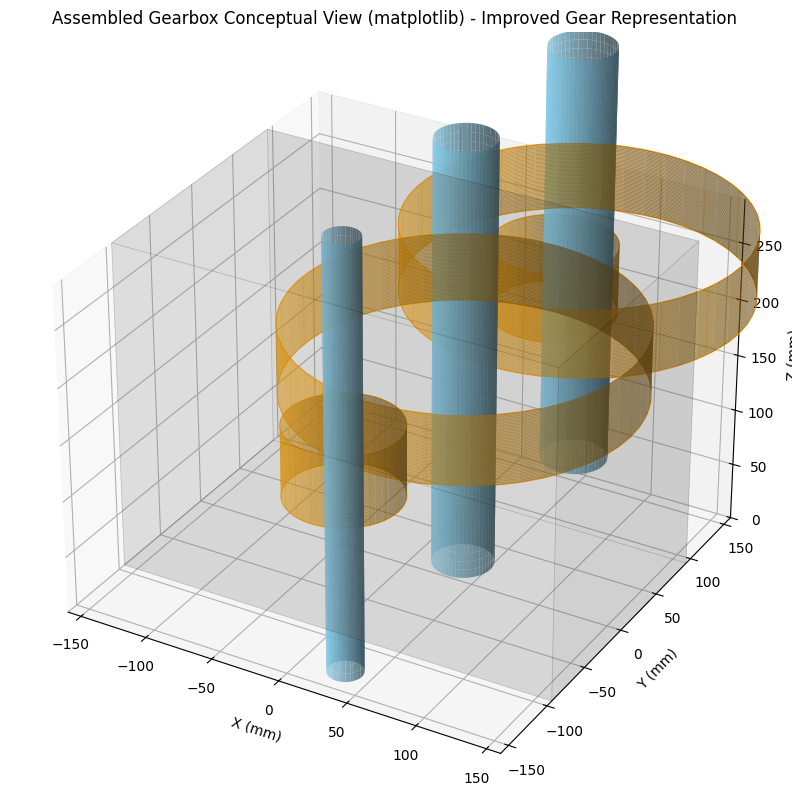

Conceptual gearbox assembly visualized with matplotlib.


In [ ]:
# In matplotlib, we will plot all components on a single 3D axis.

# Create a figure and a 3D axis
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

# Plot Housing (as a transparent box)
ax.bar3d(housing_center[0] - housing_length_x / 2,
         housing_center[1] - housing_width_y / 2,
         housing_center[2] - housing_height_z / 2,
         housing_length_x, housing_width_y, housing_height_z,
         color='gray', alpha=0.1, edgecolor='black', linewidth=0.5)

# Plot Shafts
shaft_base_color = 'skyblue'
shaft_alpha = 0.8
shaft_length_estimate = housing_length_x * 1.2 # Make shafts longer than housing for visual effect

plot_cylinder(ax, d_input_shaft / 2, shaft_length_estimate, input_shaft_center, color=shaft_base_color, alpha=shaft_alpha, label='Input Shaft')
plot_cylinder(ax, d_intermediate_shaft / 2, shaft_length_estimate, intermediate_shaft_center, color=shaft_base_color, alpha=shaft_alpha, label='Intermediate Shaft')
plot_cylinder(ax, d_output_shaft / 2, shaft_length_estimate, output_shaft_center, color=shaft_base_color, alpha=shaft_alpha, label='Output Shaft')

# Plot Gears as cylinders on their respective shafts with improved gear visualization
gear_color_main = 'orange' # Main gear body color
gear_alpha = 0.9

plot_gear_outline(ax, OD_p1_final, final_face_width, gearp1_center, color=gear_color_main, alpha=gear_alpha, label='Pinion 1')
plot_gear_outline(ax, OD_g1_final, final_face_width, gearg1_center, color=gear_color_main, alpha=gear_alpha, label='Gear 1')
plot_gear_outline(ax, OD_p2_final, final_face_width, gearp2_center, color=gear_color_main, alpha=gear_alpha, label='Pinion 2')
plot_gear_outline(ax, OD_g2_final, final_face_width, gearg2_center, color=gear_color_main, alpha=gear_alpha, label='Gear 2')

# Set labels and title
ax.set_xlabel('X (mm)')
ax.set_ylabel('Y (mm)')
ax.set_zlabel('Z (mm)')
ax.set_title('Assembled Gearbox Conceptual View (matplotlib) - Improved Gear Representation')

# Adjust axis limits to fit all components
max_dim = max(housing_length_x, housing_width_y, housing_height_z) / 2
ax.set_xlim([-max_dim, max_dim])
ax.set_ylim([-max_dim, max_dim])
ax.set_zlim([0, housing_height_z]) # Z starts from 0 for the housing base

plt.show()

print("Conceptual gearbox assembly visualized with matplotlib.")


## Assembly Visualization (Conceptual)

For an interactive visualization inside Colab, we are now using `matplotlib`. The plot above shows the assembled gearbox, allowing you to see the relative positions of the shafts and gears within a conceptual housing.

## Yeni Görselleştirme Kütüphanesi: `vedo`

`matplotlib`'in 3D modelleme yetenekleri sınırlı olduğundan, daha gerçekçi ve ayrıntılı dişli çark görselleştirmeleri için **`vedo`** kütüphanesini kullanacağız. `vedo`, bilimsel ve mühendislik verilerinin 3D görselleştirmesi için tasarlanmıştır ve `matplotlib`'e kıyasla çok daha gelişmiş özelliklere sahiptir. Öncelikle `vedo`'yu kuralım.

In [ ]:
!pip install vedo

Şimdi `vedo` kütüphanesini kullanarak bir dişli çarkı daha gerçekçi bir şekilde görselleştirmeye çalışalım. Basit bir yaklaşım olarak, temel dişli formunu oluşturmak için silindirik bir gövdeye dışarıya doğru radyal uzantılar ekleyerek dişleri taklit edeceğiz. Bu, `matplotlib`'teki çizgilere göre daha üç boyutlu bir his verecektir.

In [ ]:
import vedo
import numpy as np

# Final dişli parametrelerini kullanalım (örneğin P1)
module = final_module
Z = Z_p1  # Diş sayısı (örneğin P1 için)
face_width = final_face_width

pitch_diameter = module * Z
outer_diameter = pitch_diameter + 2 * module # Dış çap

radius_outer = outer_diameter / 2
radius_inner = pitch_diameter / 2 - module # Diş dibi için yaklaşık bir iç yarıçap

# Dişli çarkın ana silindirik gövdesini oluşturalım
gear_body = vedo.Cylinder(r=radius_inner, height=face_width, res=60, axis=(0,0,1))
gear_body.pos(0,0,0)

# Dişleri oluşturmak için bir dizi küçük kutu veya kama şekli kullanabiliriz.
# Basitlik adına, dişleri taklit etmek için silindir gövdenin etrafına küçük kutular ekleyelim.
num_teeth = Z
gear_teeth_assembly = vedo.Assembly()

tooth_width_angle = (2 * np.pi / num_teeth) * 0.4 # Diş genişliği açısı
# tooth_height = module # Dişli çarkın diş yüksekliği - (bu doğrudan kullanılmıyor, tooth_length'e dahil)

for i in range(num_teeth):
    angle = 2 * np.pi * i / num_teeth

    # Dişin radyal merkez pozisyonu
    tooth_center_r = (radius_inner + radius_outer) / 2

    # Dişin uzunluğu (radyal yönde)
    tooth_length = radius_outer - radius_inner
    # Dişin kalınlığı (teğet yönde)
    tooth_tangential_width = radius_outer * tooth_width_angle

    # Diş ilkelini (primitive) başlangıçta X ekseni boyunca, (tooth_center_r, 0, 0) noktasında ortalanmış olarak oluşturun.
    # vedo.Box(pos, length, width, height) varsayılan olarak length'i X ekseni, width'i Y eksesi, height'i Z ekseni boyunca hizalar.
    tooth_primitive = vedo.Box(
        pos=(tooth_center_r, 0, 0), # Kutunun merkezi bu noktada
        length=tooth_length,       # X ekseni boyunca dişin radyal uzunluğu
        width=tooth_tangential_width, # Y ekseni boyunca dişin teğet kalınlığı
        height=face_width          # Z ekseni boyunca dişin yüz genişliği
    )

    # Bu diş ilkelini Z ekseni etrafında, global orijin (0,0,0) merkez alınarak döndürün.
    # Bu işlem, dişi doğru açısal konuma getirir.
    tooth_primitive.rotate(np.degrees(angle), axis=(0,0,1), point=(0,0,0))

    # Diş rengini ve şeffaflığını burada uygulayın
    tooth_primitive.c("darkgoldenrod").alpha(0.9)

    gear_teeth_assembly.add(tooth_primitive)

# Dişli çark gövdesi ile dişleri birleştirme (mantıksal olarak)
# vedo'da boolean operasyonlar daha karmaşıktır, şimdilik ayrı ayrı gösterelim

# Görselleştirme
plt = vedo.Plotter(N=1, axes=4)
plt.at(0).show(gear_body.c("orange").alpha(0.8),
               gear_teeth_assembly)

# Gerekirse etkileşimli pencereyi kapatmak için
# plt.interactive().close()


## Exploded View

An exploded view shows the components separated along their assembly axes, helping to understand how they fit together. This is typically created by translating components away from the assembly center.

We will create a separate assembly for the exploded view by applying translation offsets to each component.

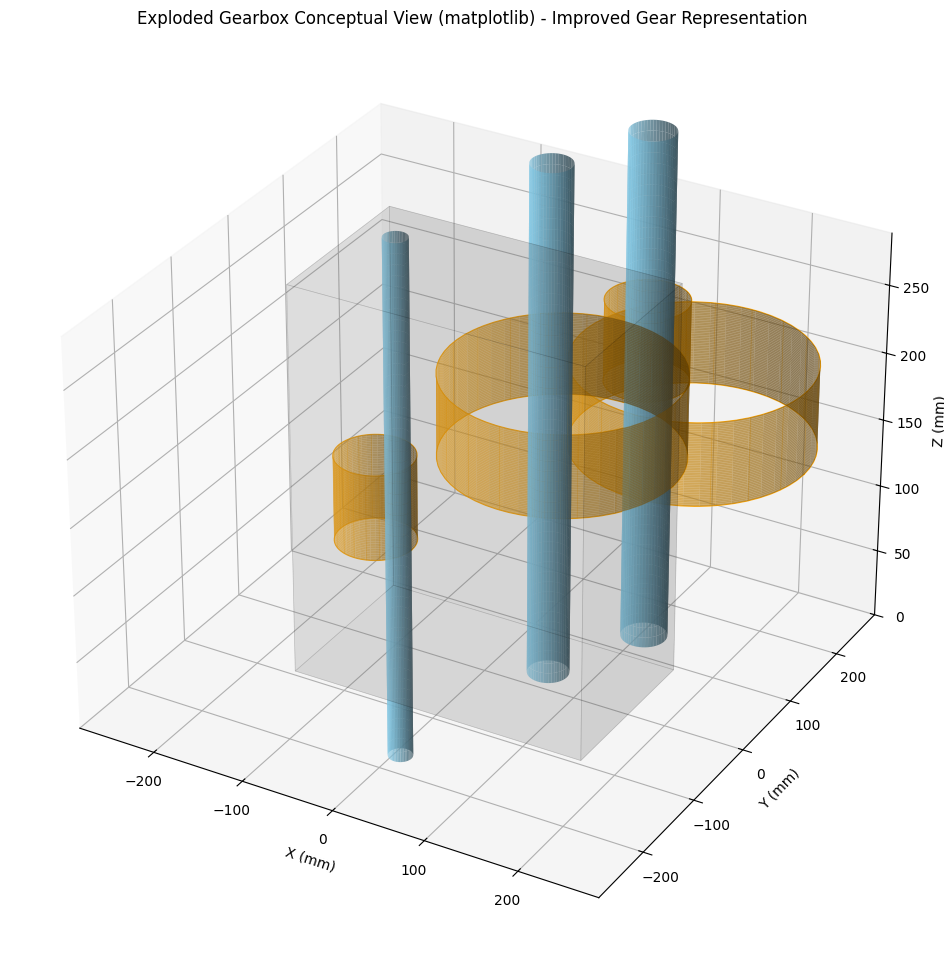

Exploded view assembly visualized with matplotlib.


In [ ]:
import matplotlib.pyplot as plt # Re-import matplotlib.pyplot

explosion_offset = 50 # mm

# Create a figure and a 3D axis for the exploded view
fig_exploded = plt.figure(figsize=(14, 12))
ax_exploded = fig_exploded.add_subplot(111, projection='3d')

# Plot Housing (transparent, no offset as it's the reference)
ax_exploded.bar3d(housing_center[0] - housing_length_x / 2,
                  housing_center[1] - housing_width_y / 2,
                  housing_center[2] - housing_height_z / 2,
                  housing_length_x, housing_width_y, housing_height_z,
                  color='gray', alpha=0.1, edgecolor='black', linewidth=0.5)

# Plot Shafts with offsets
shaft_length_estimate = housing_length_x * 1.2 # Keep consistent length

plot_cylinder(ax_exploded, d_input_shaft / 2, shaft_length_estimate,
              (input_shaft_center[0] - explosion_offset, input_shaft_center[1], input_shaft_center[2]),
              color='skyblue', alpha=0.8, label='Input Shaft Exp')
plot_cylinder(ax_exploded, d_intermediate_shaft / 2, shaft_length_estimate,
              (intermediate_shaft_center[0], intermediate_shaft_center[1] + explosion_offset, intermediate_shaft_center[2]),
              color='skyblue', alpha=0.8, label='Intermediate Shaft Exp')
plot_cylinder(ax_exploded, d_output_shaft / 2, shaft_length_estimate,
              (output_shaft_center[0] + explosion_offset, output_shaft_center[1], output_shaft_center[2]),
              color='skyblue', alpha=0.8, label='Output Shaft Exp')

# Plot Gears with offsets
gear_color_main = 'orange'

plot_gear_outline(ax_exploded, OD_p1_final, final_face_width,
                  (gearp1_center[0] - explosion_offset * 1.5, gearp1_center[1], gearp1_center[2]),
                  color=gear_color_main, alpha=0.9, label='Pinion 1 Exp')
plot_gear_outline(ax_exploded, OD_g1_final, final_face_width,
                  (gearg1_center[0], gearg1_center[1] + explosion_offset * 1.5, gearg1_center[2]),
                  color=gear_color_main, alpha=0.9, label='Gear 1 Exp')
plot_gear_outline(ax_exploded, OD_p2_final, final_face_width,
                  (gearp2_center[0], gearp2_center[1] + explosion_offset * 2.5, gearp2_center[2]), # More offset for P2
                  color=gear_color_main, alpha=0.9, label='Pinion 2 Exp')
plot_gear_outline(ax_exploded, OD_g2_final, final_face_width,
                  (gearg2_center[0] + explosion_offset * 2.0, gearg2_center[1], gearg2_center[2]), # More offset for G2
                  color=gear_color_main, alpha=0.9, label='Gear 2 Exp')

# Set labels and title
ax_exploded.set_xlabel('X (mm)')
ax_exploded.set_ylabel('Y (mm)')
ax_exploded.set_zlabel('Z (mm)')
ax_exploded.set_title('Exploded Gearbox Conceptual View (matplotlib) - Improved Gear Representation')

# Adjust axis limits to fit all components
max_offset = explosion_offset * 2.5 # Max offset for any component
ax_exploded.set_xlim([-max_dim - max_offset, max_dim + max_offset])
ax_exploded.set_ylim([-max_dim - max_offset, max_dim + max_offset])
ax_exploded.set_zlim([0, housing_height_z])

plt.show()

print("Exploded view assembly visualized with matplotlib.")

---

# PART 12: Visualization

## Matplotlib ile İnteraktif 3D Görselleştirme

`jupyter-cadquery` artık kullanılmadığı için bu bölüm de devre dışı bırakılmıştır.

In [ ]:
# jupyter-cadquery importu ve konfigürasyonu artık kullanılmıyor.

Montaj görselleştirmesi `matplotlib` tarafından sağlanacaktır.

## Interactive 3D Rendering: Exploded View

Now, let's visualize the exploded view to clearly see all individual components and their relative positions.

In [ ]:
# Patlatılmış görünüm görselleştirmesi `matplotlib` tarafından sağlanacaktır.

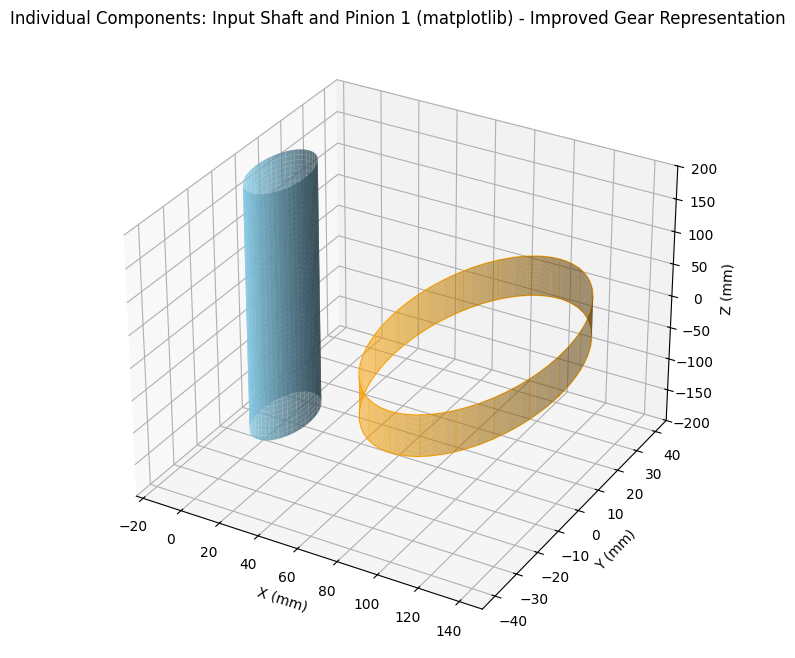

Individual components visualized with matplotlib.


In [ ]:
import matplotlib.pyplot as plt # Re-import matplotlib.pyplot

# The individual components can be conceptually plotted by calling the `plot_cylinder` function directly.
fig_indiv = plt.figure(figsize=(10, 8))
ax_indiv = fig_indiv.add_subplot(111, projection='3d')

# Plot Input Shaft
shaft_length_estimate = housing_length_x * 1.2
plot_cylinder(ax_indiv, d_input_shaft / 2, shaft_length_estimate, (0, 0, 0), color='skyblue', alpha=0.8, label='Input Shaft')

# Plot Gear P1 (placed next to the shaft for clarity)
plot_gear_outline(ax_indiv, OD_p1_final, final_face_width, (OD_p1_final + 20, 0, 0), color='orange', alpha=0.9, label='Pinion 1')

ax_indiv.set_xlabel('X (mm)')
ax_indiv.set_ylabel('Y (mm)')
ax_indiv.set_zlabel('Z (mm)')
ax_indiv.set_title('Individual Components: Input Shaft and Pinion 1 (matplotlib) - Improved Gear Representation')

plt.show()

print("Individual components visualized with matplotlib.")

## Visualization of Individual Components (Optional)

We can also visualize individual components if needed. For example, let's see the input shaft and one of the gears.

---

# PART 13: Aircraft Extension - Turboprop Reduction Gearbox

This section extends our industrial gearbox design to a highly demanding aerospace application: a turboprop reduction gearbox, specifically considering engines like the Pratt & Whitney Canada PT6A-66D and PT6E-66XT. This involves significant changes and additional design considerations compared to a ground-based industrial application.

## Transitioning from Industrial to Aerospace Gearbox

While the fundamental principles of gear meshing and power transmission remain, the context of an aircraft gearbox introduces extreme constraints and requirements that drastically alter the design approach.

## Turboprop Engines: PT6A-66D and PT6E-66XT

The PT6 family is renowned for its reliability and versatility. These are turboprop engines, meaning a gas turbine drives a propeller through a reduction gearbox. They are known for:

-   **PT6A-66D:** Max power ~850-1000 SHP (Shaft Horsepower, ~630-745 kW). Used in aircraft like the TBM 700/850.
-   **PT6E-66XT:** An advanced variant of the PT6A-66D, providing higher power (e.g., 1100 SHP / ~820 kW) and enhanced digital engine control (DEEC).

### Key Differences from our Design

Our current gearbox is a 30 kW unit. A turboprop gearbox handles significantly higher power (up to ~800 kW or more) and operates under much more stringent conditions.

## Additional Requirements for Aircraft Gearboxes

1.  **Power Levels:** Our design is 30 kW. Turboprop engines operate at hundreds of kilowatts to over a megawatt. This necessitates much larger and stronger gears, shafts, and bearings capable of handling extreme loads.
2.  **Weight Constraints:** This is paramount in aerospace. Every gram counts. Materials like maraging steels, titanium alloys, and advanced composites are used. Optimization for minimum weight becomes the primary objective.
3.  **Space Constraints:** Gearboxes must be compact to fit within the engine nacelle, influencing gear train configuration (e.g., planetary).
4.  **Reliability and Redundancy:** Catastrophic failure is unacceptable. Design for fault tolerance, redundant systems, and extremely high reliability (e.g., 1 in $10^9$ flight hours for critical components).
5.  **Vibration and Noise Reduction:** Smooth operation is crucial for passenger comfort and structural integrity. High-precision manufacturing, helical/double-helical gears, and advanced damping are employed.
6.  **Thermal Management:** Significant heat is generated due to higher power and friction. Sophisticated lubrication and cooling systems (oil jets, heat exchangers) are mandatory.
7.  **Lubrication Systems:** Pressurized oil systems are used not just for lubrication but also for cooling, hydraulic control (e.g., propeller pitch), and scavenging.
8.  **Monitoring and Health Management:** Sensors for temperature, pressure, vibration, and debris detection are integrated for predictive maintenance and real-time health monitoring.
9.  **Operating Environment:** Wide temperature ranges, varying atmospheric pressures, and exposure to extreme conditions (e.g., bird strike resilience for housing).
10. **Propeller Integration:** The gearbox must mechanically interface with and transmit thrust to the propeller, often including features for propeller pitch control mechanisms.

## Planetary Gear Systems

For turboprop reduction, **planetary gear systems** are almost universally preferred over parallel-axis (spur/helical) arrangements like our two-stage design.

**Advantages of Planetary Gears for Turboprops:**
-   **Coaxial Design:** Input and output shafts are coaxial, allowing for compact packaging directly in line with the engine turbine and propeller.
-   **High Power Density:** Multiple planet gears share the load, enabling higher torque transmission for a given size and weight.
-   **Compactness:** Efficient use of space due to the concentric arrangement.
-   **Load Sharing:** Distributes forces more evenly, reducing bearing loads and improving reliability.
-   **High Reduction Ratios:** Can achieve high reduction ratios in a single stage or multiple compact stages.

### Layout Example (Conceptual)

A typical turboprop gearbox might involve:
-   A **sun gear** connected to the turbine output shaft.
-   Multiple **planet gears** meshing with the sun gear and an external **ring gear**.
-   A **planet carrier** connected to the propeller shaft.

### Material Changes

-   **Gears:** Carburized and ground alloy steels (e.g., AISI 9310, AMS 6260), maraging steels, or other high-strength, high-toughness, and fatigue-resistant alloys.
-   **Shafts:** High-strength, high-fatigue-life alloys, often hollow to save weight.
-   **Housing:** Lightweight alloys (e.g., aluminum, magnesium, titanium) to reduce mass, while providing structural rigidity and containment.

## Certification Challenges

Aircraft components, especially those in the powertrain, are subject to rigorous certification by aviation authorities (e.g., FAA in the U.S., EASA in Europe). This involves:

1.  **Strict Design Standards:** Adherence to detailed industry standards (e.g., MIL-SPECs, SAE Aerospace Standards, ARP, AS).
2.  **Extensive Testing:** Prototype testing (endurance, overload, thermal, vibration, bird strike, debris tolerance), material property verification, fatigue life testing.
3.  **Detailed Analysis and Documentation:** Every design decision, calculation, and test result must be thoroughly documented and justified.
4.  **Traceability:** Full traceability of materials, manufacturing processes, and personnel involved.
5.  **Failure Modes and Effects Analysis (FMEA):** Comprehensive analysis of potential failure modes and their impact.
6.  **Maintenance and Repair Procedures:** Development and validation of detailed maintenance manuals.

These challenges add immense complexity, time, and cost to the development of an aerospace gearbox.

## Conclusion for Aircraft Extension

While our industrial gearbox provides a solid foundation in mechanical design principles, transforming it into a turboprop reduction gearbox for engines like the PT6A-66D or PT6E-66XT would necessitate a complete redesign. The focus would shift dramatically towards extreme power density, minimal weight, absolute reliability, advanced materials, planetary configurations, and adherence to stringent aerospace certification standards. It's a leap from robust industrial machinery to a highly optimized, safety-critical aerospace component.

---

# Project Conclusion

This comprehensive Google Colab notebook has guided us through the step-by-step design of a two-stage reduction gearbox, from theoretical foundations and fundamental calculations to 3D CAD generation, optimization, and finally, a conceptual extension to aerospace applications. We've utilized Python for all calculations, demonstrating its power as an engineering tool.

This project serves as a complete, worked example for mechanical engineers to learn or relearn the intricate process of gearbox design.

In [1]:
2+3

5

In [2]:
"2"+"3"

'23'